# Lesson 2 — Homework

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/djnzx/ida-practice-3d/blob/main/practice/2/2-homework.ipynb)

**Estimated time: 3-4 hours.**

## How to work through this

Each task gives a function signature and a docstring stating exactly what
the function must return. Replace `raise NotImplementedError` with your
implementation; the cell after it asserts the behaviour.

**A failing assert is information, not a grade.** Read it, fix the
function, re-run.

The written questions are marked and they carry the real learning
objective. Each asks you to **run something both ways and explain the
difference**, using numbers you produced. One sentence will not be enough.

Every function you need is demonstrated in `2-practice.ipynb`, and each task
names the section. You should not need any other documentation.

## Before you submit

**Runtime → Restart and run all must complete without error** with every
assert passing. Then **File → Download → Download .ipynb**, rename the file to
`2-homework-results.ipynb`, and commit it to your fork under
`practice/2/`. Keep the outputs in the file; do not clear them.
The full procedure is in `practice/README.md` §8.

## 1. Setup

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 20250919
rng = np.random.default_rng(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (7.0, 4.5)
plt.rcParams["figure.dpi"] = 110

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| seaborn", sns.__version__)

python 3.12.3 | pandas 2.2.2 | seaborn 0.13.2


In [2]:
titanic = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/titanic.csv"
)
wine = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/wine.csv"
)
bikes = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/bike_sharing_hourly.csv"
)

print("titanic", titanic.shape, "| wine", wine.shape, "| bikes", bikes.shape)

titanic (891, 12) | wine (178, 14) | bikes (17379, 17)


In [3]:
# LOCAL ALTERNATIVE. Run EITHER this cell OR the one above, not both.
# Above reads over the network and is what Colab needs. This one reads
# the same files from your checkout, for the dev-env container. The
# data is identical; only the address differs.
# Not run here: the data was read over the network by the cell above,
# so this cell is kept commented out to make Restart and run all work.
# titanic = pd.read_csv("../datasets/titanic.csv")
# wine = pd.read_csv("../datasets/wine.csv")
# bikes = pd.read_csv("../datasets/bike_sharing_hourly.csv")
#
# print("titanic", titanic.shape, "| wine", wine.shape, "| bikes", bikes.shape)

## 2. Task 1 — A missingness report

Mechanical.

*see Practice 2 §5.1*

In [4]:
def missing_report(frame):
    """Return a DataFrame describing the missing values of `frame`.

    One row per column that has at least one missing value. Columns with
    no missing values are excluded entirely.

    Two columns, in this order:
        'missing'  the count of missing values, an integer
        'percent'  the percentage of rows missing, 0-100, rounded to 2 dp

    Sorted by 'missing', descending. The index is the original column name.
    """
    counts = frame.isna().sum()
    counts = counts[counts > 0].astype(int)
    report = pd.DataFrame({
        "missing": counts,
        "percent": (100 * counts / len(frame)).round(2),
    })
    return report.sort_values("missing", ascending=False)

In [5]:
_report = missing_report(titanic)

assert list(_report.columns) == ["missing", "percent"], f"columns wrong: {list(_report.columns)}"
assert len(_report) == 3, f"Titanic has three columns with gaps, you reported {len(_report)}"
assert list(_report.index) == ["Cabin", "Age", "Embarked"], \
    f"wrong columns or wrong order: {list(_report.index)}"
assert _report.loc["Cabin", "missing"] == 687
assert _report.loc["Age", "missing"] == 177
assert _report.loc["Embarked", "missing"] == 2
assert np.isclose(_report.loc["Age", "percent"], 19.87, atol=0.01), \
    f"percent should be 100 * 177/891 = 19.87, got {_report.loc['Age', 'percent']}"

# a frame with no gaps produces an empty report, not an error
assert len(missing_report(wine)) == 0, "wine.csv has no missing values"

print(_report)
print("\nTask 1 passed.")

          missing  percent
Cabin         687  77.1000
Age           177  19.8700
Embarked        2   0.2200

Task 1 passed.


## 3. Task 2 — Label against position

Mechanical, and the trap is real. After a sort, `.loc` and `.iloc` answer
different questions.

*see Practice 2 §4*

In [6]:
def first_and_labelled(frame, sort_column, label):
    """Sort `frame` by `sort_column` descending, then return a tuple:

        (top_row, labelled_row)

    top_row       the row now in FIRST POSITION, as a Series
    labelled_row  the row whose INDEX LABEL equals `label`, as a Series

    Do not reset the index. Both must come from the sorted frame.
    """
    ordered = frame.sort_values(sort_column, ascending=False)
    top_row = ordered.iloc[0]          # position
    labelled_row = ordered.loc[label]  # label
    return top_row, labelled_row

In [7]:
_top, _labelled = first_and_labelled(titanic, "Fare", 0)

assert isinstance(_top, pd.Series) and isinstance(_labelled, pd.Series)
assert np.isclose(_top["Fare"], 512.3292), \
    f"the highest fare is 512.3292, you returned {_top['Fare']}"
assert _labelled["Name"] == "Braund, Mr. Owen Harris", \
    f"label 0 is Braund, you returned {_labelled['Name']}"
assert np.isclose(_labelled["Fare"], 7.25)
assert _top["Name"] != _labelled["Name"], \
    "position 0 and label 0 must be different passengers after sorting"

print("position 0 after sorting:", _top["Name"], "| fare", round(_top["Fare"], 2))
print("label 0 after sorting   :", _labelled["Name"], "| fare", round(_labelled["Fare"], 2))
print("\nTask 2 passed.")

position 0 after sorting: Lesurer, Mr. Gustave J | fare 512.33
label 0 after sorting   : Braund, Mr. Owen Harris | fare 7.25

Task 2 passed.


## 4. Task 3 — Group-wise imputation, without the chained-assignment bug

Applied. Fill missing ages with the median of the passenger's
`(Pclass, Sex)` group, and do it without triggering a
`SettingWithCopyWarning`.

*see Practice 2 §4.2, §5.4 and §6.3*

In [8]:
def fill_age_by_group(frame):
    """Return a COPY of `frame` with missing 'Age' filled by the median age
    of the passenger's (Pclass, Sex) group.

    The argument must not be modified.
    The returned frame must have no missing 'Age'.
    Use groupby(...).transform(...), not a loop, and not agg.
    """
    filled = frame.copy()
    group_median = filled.groupby(["Pclass", "Sex"])["Age"].transform("median")
    filled["Age"] = filled["Age"].fillna(group_median)   # one assignment on the copy
    return filled

In [9]:
import warnings

_before_missing = int(titanic["Age"].isna().sum())

with warnings.catch_warnings():
    warnings.simplefilter("error")          # any pandas warning becomes an exception
    _filled = fill_age_by_group(titanic)

assert int(titanic["Age"].isna().sum()) == _before_missing, "the argument was modified"
assert int(_filled["Age"].isna().sum()) == 0, "some ages are still missing"
assert len(_filled) == len(titanic), "rows were added or lost"

# The ages that were already present must be untouched.
_present = titanic["Age"].notna()
assert np.allclose(_filled.loc[_present, "Age"], titanic.loc[_present, "Age"]), \
    "existing ages were altered"

# A filled passenger must receive their own group's median, not the global one.
_a_gap = titanic.index[titanic["Age"].isna()][0]
_pclass, _sex = titanic.loc[_a_gap, "Pclass"], titanic.loc[_a_gap, "Sex"]
_expected = titanic[(titanic["Pclass"] == _pclass) & (titanic["Sex"] == _sex)]["Age"].median()
assert np.isclose(_filled.loc[_a_gap, "Age"], _expected), \
    f"passenger {_a_gap} got {_filled.loc[_a_gap, 'Age']}, expected group median {_expected}"

print(f"filled {_before_missing} ages; std went from "
      f"{titanic['Age'].std():.4f} to {_filled['Age'].std():.4f}")
print("Task 3 passed.")

filled 177 ages; std went from 14.5265 to 13.3044
Task 3 passed.


## 5. Task 4 — Four imputations, four distributions

Applied.

*see Practice 2 §5.4*

In [10]:
def compare_imputations(frame, column="Age"):
    """Return a DataFrame comparing four ways of handling missing values.

    Index, exactly these four labels in this order:
        'dropna', 'mean', 'median', 'group_median'

    Columns, in this order: 'n', 'mean', 'median', 'std'
        n       number of non-missing values after the strategy is applied
        mean    the mean of the resulting values
        median  the median
        std     the standard deviation (pandas default, ddof=1)

    'group_median' fills with the median of the (Pclass, Sex) group.
    """
    values = frame[column]
    group_median = frame.groupby(["Pclass", "Sex"])[column].transform("median")
    variants = {
        "dropna": values.dropna(),
        "mean": values.fillna(values.mean()),
        "median": values.fillna(values.median()),
        "group_median": values.fillna(group_median),
    }
    return pd.DataFrame({
        "n": [int(v.notna().sum()) for v in variants.values()],
        "mean": [v.mean() for v in variants.values()],
        "median": [v.median() for v in variants.values()],
        "std": [v.std() for v in variants.values()],
    }, index=list(variants))

In [11]:
_comparison = compare_imputations(titanic)

assert list(_comparison.index) == ["dropna", "mean", "median", "group_median"]
assert list(_comparison.columns) == ["n", "mean", "median", "std"]
assert _comparison.loc["dropna", "n"] == 714, "dropna keeps the 714 recorded ages"
assert _comparison.loc["mean", "n"] == 891, "filling keeps all 891 rows"

# Filling with the mean preserves the mean exactly and shrinks the spread.
assert np.isclose(_comparison.loc["mean", "mean"], titanic["Age"].mean()), \
    "filling with the mean must leave the mean unchanged"
assert _comparison.loc["mean", "std"] < _comparison.loc["dropna", "std"], \
    "stacking 177 rows on one value must reduce the standard deviation"

# The group-wise fill distorts the spread less than a single constant does.
assert _comparison.loc["group_median", "std"] > _comparison.loc["mean", "std"], \
    "the group-wise fill should preserve more of the spread than a constant fill"

print(_comparison.round(4))
print("\nTask 4 passed.")

                n    mean  median     std
dropna        714 29.6991 28.0000 14.5265
mean          891 29.6991 29.6991 13.0020
median        891 29.3616 28.0000 13.0197
group_median  891 29.1124 26.0000 13.3044

Task 4 passed.


### Question 1 — choosing an imputation

Using the table you just produced, and a histogram of each of the four
resulting distributions:

**(a)** Filling with the mean leaves the mean **exactly** unchanged and
still damages the data. What quantity did it damage, by how much, and why
does preserving the mean not make the fill harmless?

**(b)** Compare `dropna` with the three fills. Dropping loses 177 rows,
20 % of the data. Under what condition about *why* the values are missing
is dropping unbiased, and is that condition plausible for Titanic's `Age`?
Name the MCAR / MAR / MNAR category you think applies and give your
evidence.

**(c)** You must pick one strategy and defend it to a reviewer. Pick one
and write the defence in three sentences.

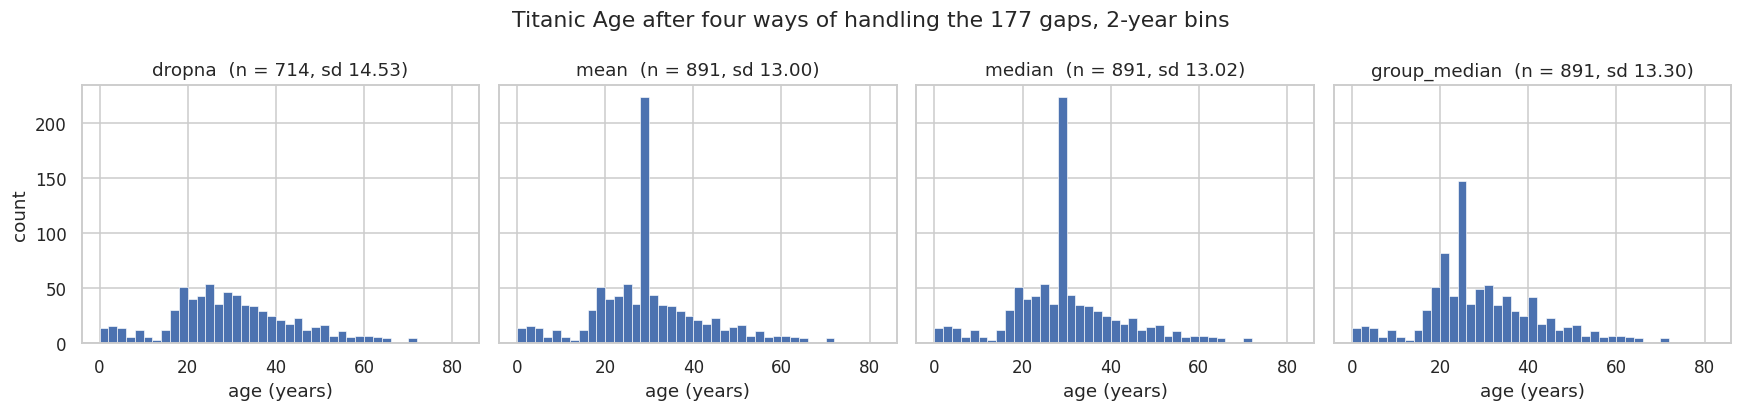

dropna        sd 14.5265 ( +0.00 % vs dropna)  most frequent single value  24.00 occurs  30 times
mean          sd 13.0020 (-10.49 % vs dropna)  most frequent single value  29.70 occurs 177 times
median        sd 13.0197 (-10.37 % vs dropna)  most frequent single value  28.00 occurs 202 times
group_median  sd 13.3044 ( -8.41 % vs dropna)  most frequent single value  25.00 occurs 117 times

group medians used by group_median:
Sex     female    male
Pclass                
1      35.0000 40.0000
2      28.0000 30.0000
3      21.5000 25.0000

share of Age missing, by group:
  Pclass    {1: 0.1389, 2: 0.0598, 3: 0.277}
  Sex       {'female': 0.1688, 'male': 0.2149}
  Embarked  {'C': 0.2262, 'Q': 0.6364, 'S': 0.1398}
  Survived  {0: 0.2277, 1: 0.152}

survival rate, Age recorded: 0.4062   Age missing: 0.2938
share of third class, Age recorded: 0.4972   Age missing: 0.7684


In [12]:
_age = titanic["Age"]
_variants = {
    "dropna": _age.dropna(),
    "mean": _age.fillna(_age.mean()),
    "median": _age.fillna(_age.median()),
    "group_median": fill_age_by_group(titanic)["Age"],
}

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
_age_edges = np.arange(0, 84, 2)
for ax, (name, values) in zip(axes, _variants.items()):
    ax.hist(values, bins=_age_edges, edgecolor="white", linewidth=0.4)
    ax.set_title(f"{name}  (n = {values.size}, sd {values.std():.2f})")
    ax.set_xlabel("age (years)")
axes[0].set_ylabel("count")
fig.suptitle("Titanic Age after four ways of handling the 177 gaps, 2-year bins")
fig.tight_layout()
plt.show()

_sd_drop = _variants["dropna"].std()
for name, values in _variants.items():
    _top = values.value_counts().iloc[0]
    print(f"{name:13} sd {values.std():7.4f} ({100 * (values.std() / _sd_drop - 1):+6.2f} % vs dropna)  "
          f"most frequent single value {values.value_counts().index[0]:6.2f} occurs {_top:3} times")

print("\ngroup medians used by group_median:")
print(titanic.groupby(["Pclass", "Sex"])["Age"].median().unstack())

# Is Age missing at random? Missingness rate against observed columns.
_gap = titanic["Age"].isna()
print("\nshare of Age missing, by group:")
for col in ("Pclass", "Sex", "Embarked", "Survived"):
    print(f"  {col:9}", titanic.groupby(col)["Age"].apply(lambda s: s.isna().mean()).round(4).to_dict())
print(f"\nsurvival rate, Age recorded: {titanic.loc[~_gap, 'Survived'].mean():.4f}   "
      f"Age missing: {titanic.loc[_gap, 'Survived'].mean():.4f}")
print(f"share of third class, Age recorded: {(titanic.loc[~_gap, 'Pclass'] == 3).mean():.4f}   "
      f"Age missing: {(titanic.loc[_gap, 'Pclass'] == 3).mean():.4f}")

**Your answer:**

**(a)** Заповнення середнім справді зберігає середнє (29,6991 до і після), але псує розкид і форму розподілу. Стандартне відхилення падає з 14,5265 до 13,0020, тобто на 10,5 %, а на гістограмі з'являється штучний пік: 177 пасажирів мають однаковий вік 29,70, хоча найчастіше реальне значення (24 роки) трапляється лише 30 разів. Медіана при цьому зсувається з 28,00 до 29,70. Збереження середнього не робить заповнення нешкідливим, бо майже все, що рахують далі, залежить не лише від середнього: дисперсія і стандартні похибки (вибірка удає, що має 891 точне значення замість 714), квантилі, кореляції віку з іншими ознаками (177 рядків з константою послаблюють будь-який зв'язок), а для моделі ще й форма розподілу. До того ж середнє спостережених значень саме по собі є правильною оцінкою лише тоді, коли пропуски випадкові, а це не так (пункт b).

**(b)** Відкидання рядків незміщене лише за умови MCAR, тобто коли факт пропуску не залежить ні від спостережених, ні від неспостережених величин. Для `Age` ця умова не виконується. Частка пропусків у першому класі 13,9 %, у другому 6,0 %, у третьому 27,7 %; серед тих, хто сів у Квінстауні, 63,6 % проти 14,0 % у Саутгемптоні; серед загиблих 22,8 % проти 15,2 % серед тих, хто вижив. Серед пасажирів з пропущеним віком 76,8 % їхали третім класом (серед решти 49,7 %), а виживаність у них 0,2938 проти 0,4062. Отже, пропуск залежить від спостережених змінних, і найправдоподібнішою є категорія **MAR**: вік гірше фіксували для пасажирів третього класу і тих, хто сідав у Квінстауні. MNAR (залежність від самого віку) виключити не можна, але перевірити його на цих даних неможливо. Відкинувши 177 рядків, ми отримали б вибірку, зміщену в бік першого класу і тих, хто вижив, наприклад з виживаністю 0,406 замість 0,384 у повних даних.

**(c)** Я обираю заповнення медіаною групи `(Pclass, Sex)`. Пропуски залежать саме від класу, тому заповнення, обумовлене класом і статтю, використовує ту інформацію, від якої залежить механізм пропуску, і дає, наприклад, чоловікам третього класу 25 років, а жінкам першого 35 замість єдиних 28 чи 29,7 для всіх. Воно зберігає всі 891 рядки, не зміщує склад вибірки, як `dropna`, і менше стискає розкид, ніж сталі заповнення (sd 13,30, тобто втрата 8,4 % проти 10,5 % у заповнення середнім), хоча й створює власний пік із 117 однакових значень 25 років, тому для статистичних висновків я додав би ознаку «вік був пропущений» і обережно ставився б до оцінок дисперсії.

## 6. Task 5 — The IQR rule

Applied. Implement the rule behind a boxplot's whiskers.

*see Practice 2 §10.4*

In [13]:
def iqr_outliers(series, multiplier=1.5):
    """Flag the values of `series` outside the 1.5 x IQR fences.

    Q1 and Q3 are the 25th and 75th percentiles; IQR = Q3 - Q1.
    The fences are Q1 - multiplier*IQR and Q3 + multiplier*IQR.
    A value strictly outside either fence is an outlier.

    Missing values are never outliers.

    Return a dict with exactly these five keys:
        'q1', 'q3', 'lower', 'upper'   the four numbers, as floats
        'mask'  a boolean Series aligned to `series`, True where outlying
    """
    q1 = float(series.quantile(0.25))     # quantile skips NaN
    q3 = float(series.quantile(0.75))
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr
    # comparisons with NaN are False, so a missing value is never flagged
    mask = ((series < lower) | (series > upper)).astype(bool)
    return {"q1": q1, "q3": q3, "lower": float(lower), "upper": float(upper), "mask": mask}

In [14]:
_fare = iqr_outliers(titanic["Fare"], multiplier=1.5)

assert set(_fare) == {"q1", "q3", "lower", "upper", "mask"}
assert np.isclose(_fare["q1"], 7.9104, atol=1e-3), f"Q1 wrong: {_fare['q1']}"
assert np.isclose(_fare["q3"], 31.0, atol=1e-6), f"Q3 wrong: {_fare['q3']}"
assert np.isclose(_fare["upper"], 65.6344, atol=1e-3), f"upper fence wrong: {_fare['upper']}"
assert _fare["mask"].dtype == bool
assert int(_fare["mask"].sum()) == 116, \
    f"the 1.5 x IQR rule flags 116 fares, you found {int(_fare['mask'].sum())}"

# A larger multiplier can never flag more points.
assert iqr_outliers(titanic["Fare"], 3.0)["mask"].sum() <= _fare["mask"].sum()

# Missing values must not be flagged.
_age_flags = iqr_outliers(titanic["Age"])["mask"]
assert not _age_flags[titanic["Age"].isna()].any(), "a missing value is not an outlier"
assert len(_age_flags) == len(titanic), "the mask must align to the input"

print(f"Fare: Q1 {_fare['q1']:.2f}, Q3 {_fare['q3']:.2f}, "
      f"fences [{_fare['lower']:.2f}, {_fare['upper']:.2f}], {int(_fare['mask'].sum())} flagged")
print("Task 5 passed.")

Fare: Q1 7.91, Q3 31.00, fences [-26.72, 65.63], 116 flagged
Task 5 passed.


### Question 2 — the multiplier, and two rules that disagree

**(a)** Run `iqr_outliers` on `Fare` at multipliers 1.0, 1.5, 3.0 and 5.0
and report the count at each. Then compute the 3σ count from Practice 1
§4.7 on the same column. Tabulate all five numbers.

**(b)** The IQR rule and the 3σ rule disagree sharply on `Fare`. Explain
*why*, referring to the shape of the distribution. Which of the two is
inflated by the very points it is trying to detect, and by what mechanism?

**(c)** Now run both rules on `Age` instead. Do they still disagree as
much? What is different about `Age` that changes the answer?

**(d)** For `Fare`, would you remove any of the flagged points? Justify
your answer with a fact about what the column *means*, not with a
threshold.

--- Fare ---
           upper fence  flagged
rule                           
IQR x 1.0      54.0900      141
IQR x 1.5      65.6300      116
IQR x 3.0     100.2700       53
IQR x 5.0     146.4500       31
3 sigma       181.2000       20
mean 32.20, median 14.45, sd 49.67, skewness 4.79, max 512.33

--- Age ---
           upper fence  flagged
rule                           
IQR x 1.0      55.8800       63
IQR x 1.5      64.8100       11
IQR x 3.0      91.6200        0
IQR x 5.0     127.3800        0
3 sigma        73.2500        2
mean 29.70, median 28.00, sd 14.52, skewness 0.39, max 80.00

Fare sd with all rows 49.67; without the 116 IQR-flagged fares 13.57
3-sigma upper fence with all rows 181.20; computed from the inner fares 58.53

who the 1.5 x IQR rule flags on Fare:
  by class: {1: 104, 2: 5, 3: 7}
  survival rate of flagged 0.6810 vs the rest 0.3394
  zero fares: 15   fares of exactly 512.3292: 3


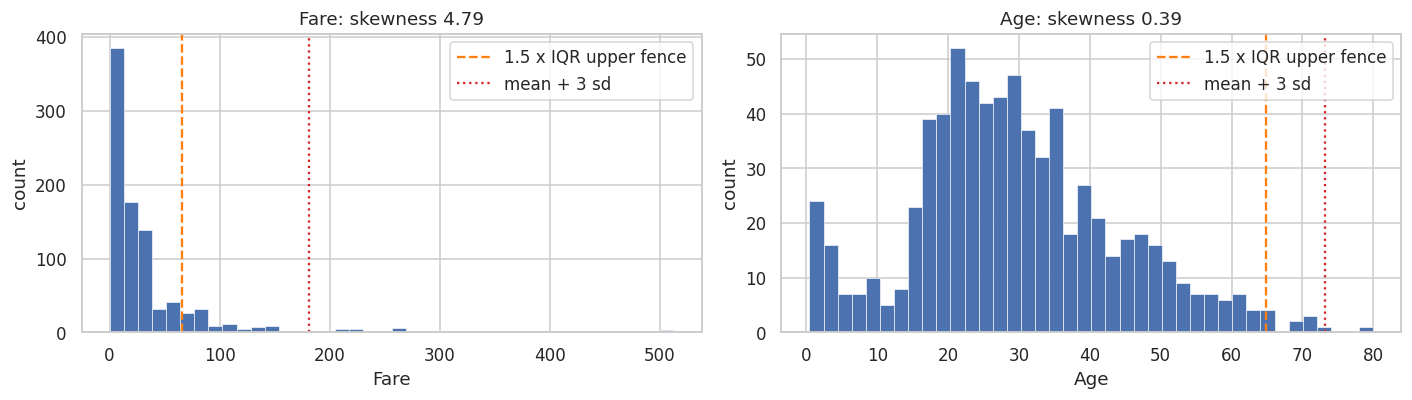

In [15]:
def three_sigma_count(series):
    """Practice 1 §4.7 on a pandas column: |x - mean| > 3 sd, NumPy's ddof=0, NaN dropped."""
    values = series.dropna().to_numpy()
    mask = np.abs(values - values.mean()) > 3 * values.std()
    return int(mask.sum()), values.mean() + 3 * values.std()

for col in ("Fare", "Age"):
    print(f"--- {col} ---")
    rows = []
    for mult in (1.0, 1.5, 3.0, 5.0):
        r = iqr_outliers(titanic[col], mult)
        rows.append({"rule": f"IQR x {mult}", "upper fence": r["upper"], "flagged": int(r["mask"].sum())})
    n3, fence3 = three_sigma_count(titanic[col])
    rows.append({"rule": "3 sigma", "upper fence": fence3, "flagged": n3})
    print(pd.DataFrame(rows).set_index("rule").round(2).to_string())
    s = titanic[col].dropna()
    print(f"mean {s.mean():.2f}, median {s.median():.2f}, sd {s.std(ddof=0):.2f}, "
          f"skewness {s.skew():.2f}, max {s.max():.2f}\n")

# Mechanism: how much the extremes inflate the sd that defines their own fence
_fare = titanic["Fare"]
_fare_flags = iqr_outliers(_fare, 1.5)["mask"]
_inner = _fare[~_fare_flags]
print(f"Fare sd with all rows {_fare.std(ddof=0):.2f}; without the 116 IQR-flagged fares {_inner.std(ddof=0):.2f}")
print(f"3-sigma upper fence with all rows {_fare.mean() + 3 * _fare.std(ddof=0):.2f}; "
      f"computed from the inner fares {_inner.mean() + 3 * _inner.std(ddof=0):.2f}")

print("\nwho the 1.5 x IQR rule flags on Fare:")
print("  by class:", titanic.loc[_fare_flags, "Pclass"].value_counts().sort_index().to_dict())
print(f"  survival rate of flagged {titanic.loc[_fare_flags, 'Survived'].mean():.4f} "
      f"vs the rest {titanic.loc[~_fare_flags, 'Survived'].mean():.4f}")
print("  zero fares:", int((_fare == 0).sum()), "  fares of exactly 512.3292:", int((_fare == _fare.max()).sum()))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col in zip(axes, ("Fare", "Age")):
    s = titanic[col].dropna()
    ax.hist(s, bins=40, edgecolor="white", linewidth=0.4)
    ax.axvline(iqr_outliers(titanic[col], 1.5)["upper"], color="tab:orange", linestyle="--",
               label="1.5 x IQR upper fence")
    ax.axvline(three_sigma_count(titanic[col])[1], color="tab:red", linestyle=":",
               label="mean + 3 sd")
    ax.set_xlabel(col)
    ax.set_ylabel("count")
    ax.set_title(f"{col}: skewness {s.skew():.2f}")
    ax.legend()
fig.tight_layout()
plt.show()

**Your answer:**

**(a)** Кількість позначених значень `Fare`:

| правило | верхня межа | позначено |
|---|---|---|
| IQR × 1,0 | 54,09 | 141 |
| IQR × 1,5 | 65,63 | 116 |
| IQR × 3,0 | 100,27 | 53 |
| IQR × 5,0 | 146,45 | 31 |
| 3σ (Practice 1 §4.7) | 181,20 | 20 |

**(b)** Розбіжність пояснюється формою розподілу. `Fare` має сильну правосторонню асиметрію (коефіцієнт асиметрії 4,79): середнє 32,20 більш ніж удвічі перевищує медіану 14,45, а максимум 512,33. Правило IQR будує межі за квартилями 7,91 і 31,00, які визначаються центральною половиною даних і не реагують на крайні значення, тому межа 65,63 лежить близько до основної маси і весь довгий хвіст позначається. Правило 3σ використовує середнє і стандартне відхилення, а обидва вони роздуваються саме тими значеннями, які правило має знайти. Зі всіма рядками sd дорівнює 49,67, а без 116 позначених тарифів лише 13,57; межа mean + 3sd відповідно 181,20 проти 58,53. Отже, роздутим виявляється правило 3σ: великі тарифи збільшують sd, що розсуває межу і ховає їх самих (ефект маскування). Крім того, 3σ неявно припускає симетричний нормальний розподіл, якого тут немає, і нижня межа виходить від'ємною, тобто безглуздою для ціни.

**(c)** Для `Age` правила розходяться значно менше в абсолютних числах: IQR × 1,5 позначає 11 пасажирів (межа 64,81), 3σ лише 2 (межа 73,25), а IQR × 3,0 і × 5,0 не позначають нікого. Вік майже симетричний (асиметрія 0,39, середнє 29,70 близьке до медіани 28,00) і обмежений природним діапазоном до 80 років, тому середнє і sd не спотворені хвостом, а обидва правила говорять про ту саму невелику групу літніх пасажирів 65–80 років, які є цілком реальними людьми.

**(d)** Жодного значення `Fare` я б не видаляв. Стовпець означає фактично сплачену ціну квитка, і великі тарифи є справжніми квитками першого класу: зі 116 позначених 104 належать першому класу, а їхня виживаність 0,681 проти 0,339 у решти. Видалити їх означало б видалити той ефект, який ми досліджуємо (Practice 2 §10.5). Тариф 512,33 трапляється тричі, це один квиток на групу, а не помилка введення. Сумнівними за змістом є радше 15 нульових тарифів, бо нуль тут є способом запису, а не ціною, і їх варто розглядати як пропуски. Для моделей з асиметрією краще працювати через логарифм тарифу або стійкі до викидів методи, а не через видалення.

## 7. Task 6 — Pearson against Spearman

Applied. Two coefficients, two different questions about the same pair of
columns.

*see Practice 2 §11.2*

In [16]:
def correlation_pair(frame, column_a, column_b):
    """Compare the two correlation coefficients for one pair of columns.

    Return a dict with exactly these three keys:
        'pearson'     the Pearson coefficient, measuring LINEAR association
        'spearman'    the Spearman coefficient, measuring MONOTONIC association
        'difference'  pearson - spearman

    Use pandas' Series.corr(method=...). Return Python floats.
    """
    a, b = frame[column_a], frame[column_b]
    pearson = float(a.corr(b, method="pearson"))
    spearman = float(a.corr(b, method="spearman"))
    return {"pearson": pearson, "spearman": spearman, "difference": pearson - spearman}

In [17]:
_pair = correlation_pair(wine, "flavanoids", "total_phenols")

assert set(_pair) == {"pearson", "spearman", "difference"}
assert np.isclose(_pair["pearson"], 0.8646, atol=1e-3), f"pearson wrong: {_pair['pearson']}"
assert np.isclose(_pair["spearman"], 0.8794, atol=1e-3), f"spearman wrong: {_pair['spearman']}"
assert np.isclose(_pair["difference"], _pair["pearson"] - _pair["spearman"])

# A perfectly linear pair: both coefficients are exactly 1.
_linear = pd.DataFrame({"a": [1.0, 2.0, 3.0, 4.0, 5.0], "b": [3.0, 5.0, 7.0, 9.0, 11.0]})
_lin = correlation_pair(_linear, "a", "b")
assert np.isclose(_lin["pearson"], 1.0) and np.isclose(_lin["spearman"], 1.0)

# Monotonic but strongly curved: Spearman sees it fully, Pearson does not.
_curve_rng = np.random.default_rng(SEED)
_x = np.linspace(0.1, 5.0, 300)
_curved = pd.DataFrame({"x": _x, "y": np.exp(_x) + _curve_rng.normal(0, 3, 300)})
_c = correlation_pair(_curved, "x", "y")
assert _c["spearman"] > 0.95, f"a monotonic pair should have Spearman near 1, got {_c['spearman']:.4f}"
assert _c["pearson"] < _c["spearman"] - 0.05, \
    "on a curved monotonic pair Pearson must fall clearly below Spearman"

print(f"wine flavanoids vs total_phenols: pearson {_pair['pearson']:+.4f}  "
      f"spearman {_pair['spearman']:+.4f}")
print(f"curved monotonic pair          : pearson {_c['pearson']:+.4f}  "
      f"spearman {_c['spearman']:+.4f}")
print("Task 6 passed.")

wine flavanoids vs total_phenols: pearson +0.8646  spearman +0.8794
curved monotonic pair          : pearson +0.8605  spearman +0.9653
Task 6 passed.


### Question 3 — two coefficients, and the bandwidth that shapes what you see

**(a)** Scatter-plot the curved pair `_curved` from the cell above. Both
coefficients are high, and they disagree by about 0.10. Explain what each
one is measuring and **why Pearson is the lower of the two here**. Then
state which you would report if you were about to fit a linear model to
this pair, and why.

**(b)** Run `correlation_pair` on `color_intensity` against `hue` in the
wine data. Here the two differ in a different way. Plot the pair and
explain what feature of the data produces the gap.

**(c)** Now a different decision that changes what you see. Take Titanic's
`Age` and draw `sns.kdeplot` at `bw_adjust` = 0.2, 1.0 and 3.0, then draw
a histogram of the same column at 20 and at 200 bins. **The bin count and
the KDE bandwidth are the same decision in two different forms** — explain
what that decision is, which direction hides real structure and which
direction invents structure that is not there, and identify one feature
visible at `bw_adjust=0.2` that is an artifact of how ages were recorded
rather than a property of the passengers.

(a) straight-line fit leaves residuals from -27.2 to 70.0; share of variance explained 0.7404
    Pearson on the ranks = 0.9653 = Spearman on the values

(b) color_intensity vs hue: pearson -0.5218  spearman -0.4185  difference -0.1033
    cultivar 0: n = 59  pearson +0.0282  spearman -0.0182  color_intensity 3.52-8.90  hue 0.82-1.28
    cultivar 1: n = 71  pearson -0.0261  spearman +0.0284  color_intensity 1.28-6.00  hue 0.69-1.71
    cultivar 2: n = 48  pearson -0.5686  spearman -0.5820  color_intensity 3.85-13.00  hue 0.48-0.96


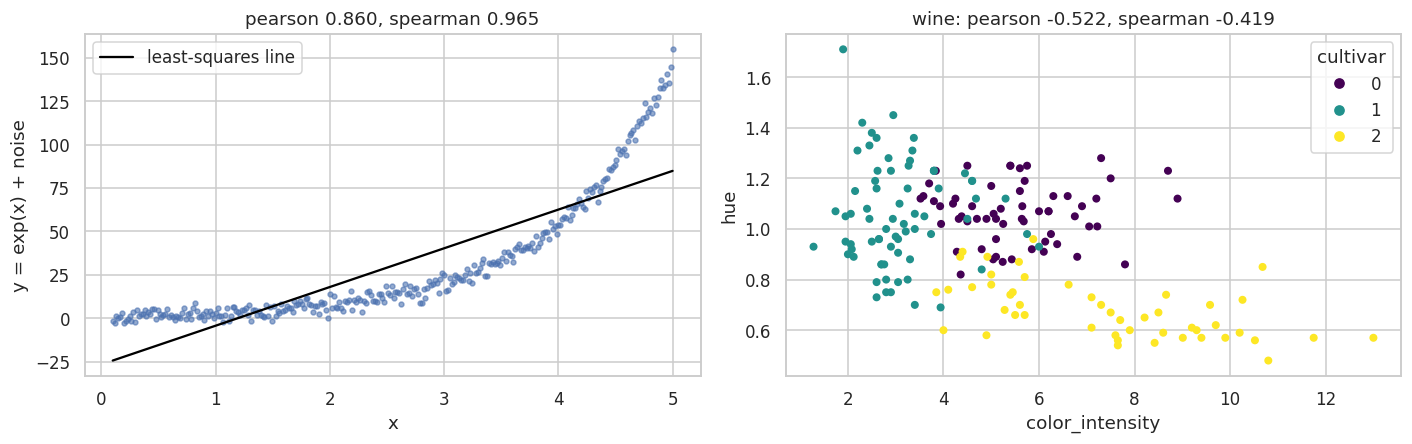

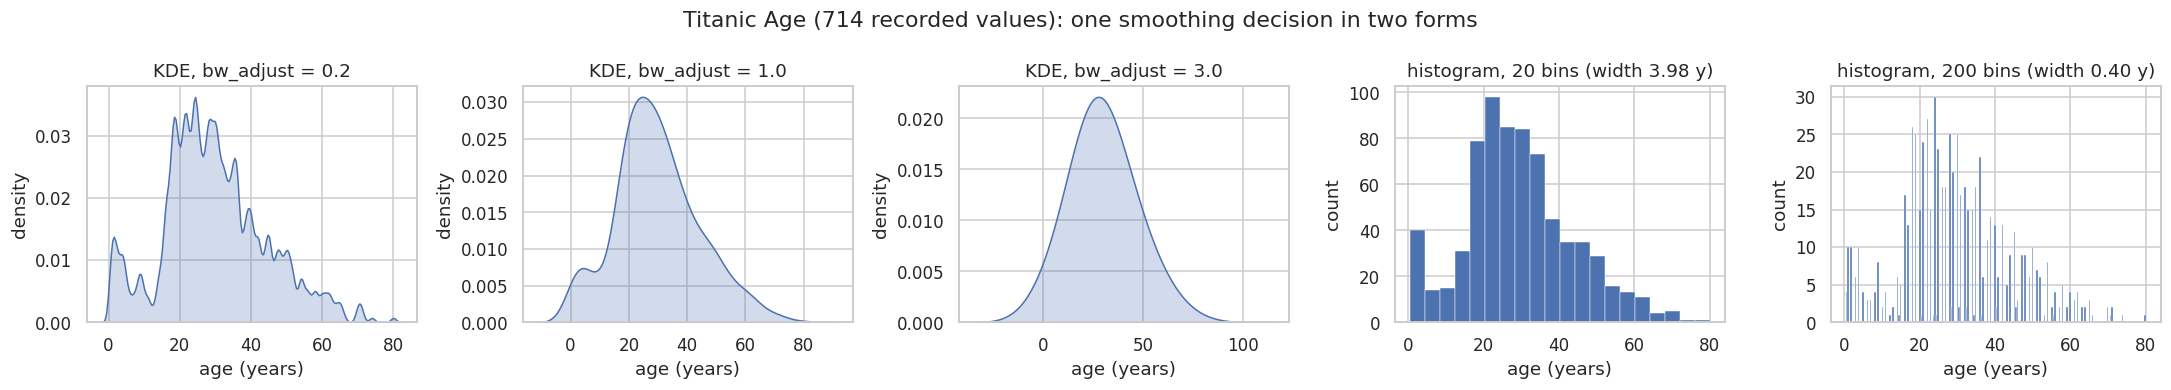

(c) whole-number ages 0.9650, ages ending in .5 0.0252, under one year 7
    200 bins: 116 of 200 bins are empty
    mean count at ages 20, 25, ..., 60: 14.1  vs at their neighbours: 13.3
    bw_adjust 0.2: bandwidth  0.78 years, probability mass placed below age 0: 0.0028
    bw_adjust 1.0: bandwidth  3.90 years, probability mass placed below age 0: 0.0176
    bw_adjust 3.0: bandwidth 11.71 years, probability mass placed below age 0: 0.0503


In [18]:
# (a) the curved pair
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].scatter(_curved["x"], _curved["y"], s=10, alpha=0.6)
_slope, _icept = np.polyfit(_curved["x"], _curved["y"], 1)
axes[0].plot(_curved["x"], _slope * _curved["x"] + _icept, color="black", label="least-squares line")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y = exp(x) + noise")
axes[0].set_title(f"pearson {_c['pearson']:.3f}, spearman {_c['spearman']:.3f}")
axes[0].legend()
_resid = _curved["y"] - (_slope * _curved["x"] + _icept)
print(f"(a) straight-line fit leaves residuals from {_resid.min():.1f} to {_resid.max():.1f}; "
      f"share of variance explained {_c['pearson'] ** 2:.4f}")
_rank_corr = _curved["x"].rank().corr(_curved["y"].rank())
print(f"    Pearson on the ranks = {_rank_corr:.4f} = Spearman on the values")

# (b) wine: color_intensity against hue
_ch = correlation_pair(wine, "color_intensity", "hue")
print(f"\n(b) color_intensity vs hue: pearson {_ch['pearson']:+.4f}  spearman {_ch['spearman']:+.4f}  "
      f"difference {_ch['difference']:+.4f}")
for cultivar, part in wine.groupby("target"):
    pc = correlation_pair(part, "color_intensity", "hue")
    print(f"    cultivar {cultivar}: n = {len(part):2}  pearson {pc['pearson']:+.4f}  spearman {pc['spearman']:+.4f}"
          f"  color_intensity {part['color_intensity'].min():.2f}-{part['color_intensity'].max():.2f}"
          f"  hue {part['hue'].min():.2f}-{part['hue'].max():.2f}")
_sc = axes[1].scatter(wine["color_intensity"], wine["hue"], c=wine["target"], cmap="viridis", s=18)
axes[1].set_xlabel("color_intensity")
axes[1].set_ylabel("hue")
axes[1].set_title(f"wine: pearson {_ch['pearson']:+.3f}, spearman {_ch['spearman']:+.3f}")
axes[1].legend(*_sc.legend_elements(), title="cultivar")
fig.tight_layout()
plt.show()

# (c) bandwidth and bin count on Titanic Age
_ages = titanic["Age"].dropna()
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, adjust in zip(axes[:3], (0.2, 1.0, 3.0)):
    sns.kdeplot(x=_ages, bw_adjust=adjust, fill=True, ax=ax)
    ax.set_title(f"KDE, bw_adjust = {adjust}")
    ax.set_xlabel("age (years)")
    ax.set_ylabel("density")
for ax, bins in zip(axes[3:], (20, 200)):
    ax.hist(_ages, bins=bins, edgecolor="white", linewidth=0.3)
    ax.set_title(f"histogram, {bins} bins (width {(_ages.max() - _ages.min()) / bins:.2f} y)")
    ax.set_xlabel("age (years)")
    ax.set_ylabel("count")
fig.suptitle("Titanic Age (714 recorded values): one smoothing decision in two forms")
fig.tight_layout()
plt.show()

_whole = (_ages == _ages.round()).mean()
_half = ((_ages * 2) == (_ages * 2).round()).mean() - _whole
print(f"(c) whole-number ages {_whole:.4f}, ages ending in .5 {_half:.4f}, "
      f"under one year {int((_ages < 1).sum())}")
_counts_age = _ages[_ages >= 1].round().value_counts().sort_index()
_c200, _e200 = np.histogram(_ages, bins=200)
print(f"    200 bins: {int((_c200 == 0).sum())} of 200 bins are empty")
_round = [a for a in range(20, 61, 5)]
_neigh = [a + d for a in _round for d in (-1, 1)]
print(f"    mean count at ages 20, 25, ..., 60: {_counts_age.reindex(_round).fillna(0).mean():.1f}  "
      f"vs at their neighbours: {_counts_age.reindex(_neigh).fillna(0).mean():.1f}")
from scipy.stats import gaussian_kde
for adjust in (0.2, 1.0, 3.0):
    _kde = gaussian_kde(_ages, bw_method="scott")
    _kde.set_bandwidth(_kde.factor * adjust)          # what seaborn's bw_adjust does
    print(f"    bw_adjust {adjust}: bandwidth {np.sqrt(_kde.covariance[0, 0]):5.2f} years, "
          f"probability mass placed below age 0: {_kde.integrate_box_1d(-np.inf, 0):.4f}")

**Your answer:**

**(a)** На діаграмі розсіювання залежність явно експоненційна. Коефіцієнт Пірсона (0,8605) вимірює, наскільки добре точки лягають на пряму, тобто лінійний зв'язок. Коефіцієнт Спірмена (0,9653) є коефіцієнтом Пірсона, обчисленим на рангах (я перевірив, що вони збігаються), і вимірює монотонність: чи зростає y, коли зростає x. Монотонність тут майже ідеальна, і Спірмен не дорівнює одиниці лише через шум при малих x, де exp(x) майже пласка. Пірсон нижчий, бо пряма не відтворює кривизну: вона завищує значення в середині й занижує на краях, залишки від −27,2 до 70,0, а частка поясненої дисперсії r² = 0,7404. Перед підгонкою лінійної моделі я звітував би про Пірсона, бо саме він показує, скільки може дати пряма (r² збігається з R² простої лінійної регресії), тоді як Спірмен переоцінив би її можливості. Сама різниця між коефіцієнтами є сигналом, що варто перетворити y (наприклад, логарифмом) або взяти нелінійну модель.

**(b)** Для `color_intensity` і `hue` Пірсон дорівнює −0,5218, Спірмен −0,4185, тобто тепер **Пірсон більший за модулем** на 0,10. Розфарбування за сортом показує, звідки це береться. Усередині сортів 0 і 1 зв'язку практично немає (коефіцієнти від −0,03 до +0,03), і лише сорт 2 утворює окрему групу в куті з великою інтенсивністю кольору (3,85–13,00) і низьким відтінком (0,48–0,96). Загальна кореляція виникає переважно через різницю між групами і через кілька вин сорту 2 з дуже великою інтенсивністю (до 13), які лежать далеко від середнього. Пірсон зважує точки за квадратом відхилень, тому ці віддалені точки сильно його підсилюють, а Спірмен перетворює їх просто на найбільші ранги й не дає їм додаткової ваги.

**(c)** Кількість бінів і ширина ядра KDE є одним рішенням: наскільки широку околицю ми усереднюємо, щоб оцінити щільність у точці, тобто вибір між зміщенням і дисперсією оцінки. Надмірне згладжування ховає реальну структуру. При `bw_adjust = 3.0` (ширина ядра 11,7 року) дитячий пік, добре помітний на гістограмі з 20 бінами (близько 40 дітей у першому біні) і як «плече» при `bw_adjust = 1.0`, зникає повністю, крива стає одним симетричним горбом і відносить 5,0 % імовірності до від'ємного віку (при 1,0 це 1,8 %). Недостатнє згладжування вигадує структуру, якої немає: при `bw_adjust = 0.2` (ширина 0,78 року) крива вкрита дрібними піками, а при 200 бінах шириною 0,40 року 116 бінів із 200 порожні, і гістограма перетворюється на гребінку. Ця гребінка і хвилястість при 0,2 є артефактом запису віку, а не властивістю пасажирів: 96,5 % віків записано цілими числами, ще 2,5 % мають вигляд xx,5 (за описом набору на Kaggle так позначено оцінений вік), а вік немовлят (7 осіб) записано дробом. Коли бін вужчий за рік, біни між цілими числами порожніють, і чергування піків відображає округлення до років. Перевірка кратних п'яти років дала слабкий ефект (у середньому 14,1 пасажира на вік 20, 25, …, 60 проти 13,3 на сусідні), тож головний артефакт саме округлення до цілих.

## 8. Task 7 — Encoding, and the distances it invents

Applied. Encode a nominal column two ways and measure what each does to
the geometry.

*see Practice 2 §13*

In [19]:
from itertools import combinations

def encoding_distances(series):
    """Compare label encoding against one-hot encoding on a nominal column.

    `series` holds categorical text with no missing values.

    Build both encodings:
      - label:   the categories sorted alphabetically, mapped to 0, 1, 2, ...
      - one-hot: one binary column per category

    Then, for every unordered pair of DISTINCT categories, compute the
    Euclidean distance between their encodings under each scheme.

    Return a DataFrame with one row per pair, indexed by the string
    "A|B" with A and B in alphabetical order, and two columns:
        'label_distance'    |code(A) - code(B)|
        'onehot_distance'   the Euclidean distance between the two one-hot rows

    Rows sorted by index.
    """
    categories = sorted(series.unique())
    label_code = {cat: i for i, cat in enumerate(categories)}
    onehot = pd.get_dummies(series, dtype=float)[categories]
    # the one-hot vector of a category is the row of any passenger with it
    vectors = {cat: onehot[series == cat].iloc[0].to_numpy() for cat in categories}

    rows = {}
    for a, b in combinations(categories, 2):
        rows[f"{a}|{b}"] = {
            "label_distance": float(abs(label_code[a] - label_code[b])),
            "onehot_distance": float(np.linalg.norm(vectors[a] - vectors[b])),
        }
    result = pd.DataFrame.from_dict(rows, orient="index")
    return result[["label_distance", "onehot_distance"]].sort_index()

In [20]:
_embarked = titanic["Embarked"].fillna("S")
_distances = encoding_distances(_embarked)

assert list(_distances.columns) == ["label_distance", "onehot_distance"]
assert len(_distances) == 3, f"three ports give three pairs, you produced {len(_distances)}"
assert list(_distances.index) == ["C|Q", "C|S", "Q|S"], f"index wrong: {list(_distances.index)}"

# Label encoding invents an ordering: C and S end up twice as far apart.
assert np.isclose(_distances.loc["C|Q", "label_distance"], 1.0)
assert np.isclose(_distances.loc["C|S", "label_distance"], 2.0)
assert np.isclose(_distances.loc["Q|S", "label_distance"], 1.0)

# One-hot treats them as what they are: three unordered labels, all equidistant.
assert np.allclose(_distances["onehot_distance"], np.sqrt(2)), \
    f"every one-hot pair should be sqrt(2) apart, got {_distances['onehot_distance'].tolist()}"
assert _distances["onehot_distance"].nunique() == 1, \
    "one-hot must not distinguish any pair from any other"

print(_distances.round(4))
print("\nTask 7 passed.")

     label_distance  onehot_distance
C|Q          1.0000           1.4142
C|S          2.0000           1.4142
Q|S          1.0000           1.4142

Task 7 passed.


### Question 4 — label against one-hot

**(a)** Under label encoding, C and S are 2 apart while C and Q are 1
apart. Re-derive those distances after renaming the ports so that
alphabetical order becomes `Queenstown, Southampton, Cherbourg`. What
happens to the geometry? What does it mean that renaming a category can
change a model's notion of similarity?

**(b)** `Pclass` also becomes integers 1, 2, 3, and Practice 2 §13.3 says
that is **correct**. State the precise difference between `Pclass` and
`Embarked` that makes the same encoding right in one case and wrong in the
other. Your answer must not mention the data type.

**(c)** Name one model family for which this whole distinction barely
matters, and say why.

In [21]:
# (a) rename the ports so that alphabetical order becomes Queenstown, Southampton, Cherbourg
_rename = {"Q": "port_1_Queenstown", "S": "port_2_Southampton", "C": "port_3_Cherbourg"}
_renamed = _embarked.map(_rename)
print("alphabetical order after renaming:", sorted(_renamed.unique()))
print(encoding_distances(_renamed).round(4))
print("\noriginal names, for comparison:")
print(encoding_distances(_embarked).round(4))

# (b) does the integer order mean anything?
print("\nsurvival rate by Pclass (order 1 < 2 < 3):")
print(titanic.groupby("Pclass")["Survived"].mean().round(4).to_dict())
print("median fare by Pclass:", titanic.groupby("Pclass")["Fare"].median().round(2).to_dict())
print("survival rate by port, alphabetical:", titanic.groupby(_embarked)["Survived"].mean().round(4).to_dict())

# (c) a tree against a distance-based model, each fed both encodings of Embarked
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

_base = fill_age_by_group(titanic)
_base_X = pd.DataFrame({"Pclass": _base["Pclass"], "Sex": (_base["Sex"] == "female").astype(int),
                        "Age": _base["Age"], "Fare": _base["Fare"]})
_codes_alpha = _embarked.map({"C": 0, "Q": 1, "S": 2})
_codes_other = _embarked.map({"Q": 0, "S": 1, "C": 2})
_designs = {
    "label C<Q<S": _base_X.assign(embarked=_codes_alpha),
    "label Q<S<C": _base_X.assign(embarked=_codes_other),
    "one-hot": pd.concat([_base_X, pd.get_dummies(_embarked, prefix="emb", dtype=int)], axis=1),
}
_cv_enc = StratifiedKFold(5, shuffle=True, random_state=SEED)
_models = {
    "tree, depth 4": DecisionTreeClassifier(max_depth=4, random_state=SEED),
    "kNN, k = 5": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
print()
for mname, model in _models.items():
    scores = {d: cross_val_score(model, X.values, titanic["Survived"].values, cv=_cv_enc).mean()
              for d, X in _designs.items()}
    print(f"{mname:14}", "  ".join(f"{d}: {s:.4f}" for d, s in scores.items()))

alphabetical order after renaming: ['port_1_Queenstown', 'port_2_Southampton', 'port_3_Cherbourg']
                                      label_distance  onehot_distance
port_1_Queenstown|port_2_Southampton          1.0000           1.4142
port_1_Queenstown|port_3_Cherbourg            2.0000           1.4142
port_2_Southampton|port_3_Cherbourg           1.0000           1.4142

original names, for comparison:
     label_distance  onehot_distance
C|Q          1.0000           1.4142
C|S          2.0000           1.4142
Q|S          1.0000           1.4142

survival rate by Pclass (order 1 < 2 < 3):
{1: 0.6296, 2: 0.4728, 3: 0.2424}
median fare by Pclass: {1: 60.29, 2: 14.25, 3: 8.05}
survival rate by port, alphabetical: {'C': 0.5536, 'Q': 0.3896, 'S': 0.339}

tree, depth 4  label C<Q<S: 0.8104  label Q<S<C: 0.8047  one-hot: 0.8104


kNN, k = 5     label C<Q<S: 0.7935  label Q<S<C: 0.7958  one-hot: 0.7913


**Your answer:**

**(a)** Після перейменування алфавітний порядок стає Queenstown, Southampton, Cherbourg, і коди змінюються на Q = 0, S = 1, C = 2. Відстані при мітковому кодуванні тепер такі: Q–S 1, S–C 1, а Q–C 2. Раніше найдальшою парою були C і S, тепер нею стали C і Q, тоді як C і S «зблизилися». One-hot відстані не змінилися: усі три пари, як і раніше, віддалені на √2 = 1,4142. Отже, геометрію міткового кодування визначає правопис, а не дані: модель, що використовує відстані або лінійну комбінацію коду, отримає інше уявлення про те, які порти «схожі», лише через перейменування категорії в базі даних. Показово, що виживаність за портами (C 0,5536, Q 0,3896, S 0,3390) випадково спадає саме в алфавітному порядку, і після перейменування цей збіг зникає. Властивість, яка залежить від назв, не може бути властивістю пасажирів.

**(b)** Для `Pclass` порядок 1 < 2 < 3 існує поза кодуванням: класи є рангами одного й того ж виміру, і з ним монотонно узгоджуються ціна (медіанний тариф 60,29, 14,25, 8,05), розташування палуб і виживаність (0,6296, 0,4728, 0,2424). Будь-яке перекодування, що зберігає цей реальний порядок, дає ту саму структуру. Порти посадки є назвами місць без власного порядку, і будь-який порядок їм нав'язує лише алфавіт. Для `Pclass` рівні кроки між кодами теж є припущенням, але принаймні напрям порядку реальний.

**(c)** Майже байдужа ця різниця для дерев рішень (і лісів з них). Дерево ділить дані порогами по одній ознаці й не обчислює відстаней, тож будь-яку категорію з трьох можна виділити щонайбільше двома розбиттями, і хибний порядок коштує в гіршому разі зайвого розбиття, а не спотвореної геометрії. У моєму порівнянні дерево глибини 4 дало 0,8104 з алфавітними кодами, 0,8104 з one-hot і 0,8047 з іншим порядком кодів. kNN на цих даних теж змінився мало (0,7935, 0,7958, 0,7913), але з іншої причини: `Embarked` має лише три категорії і є слабким предиктором (Practice 3 §10.2), тоді як для дерева стійкість закладена в самій будові моделі.

## 9. Task 8 — Scale without leaking

Applied. Split, then fit the scaler on the training half only.

*see Practice 2 §14.3*

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def split_and_scale(X, y, test_size=0.3, random_state=SEED):
    """Split into train and test, then standardise WITHOUT leakage.

    Split first with train_test_split, stratifying on y and using the
    given random_state. Then fit a StandardScaler on the TRAINING features
    only, and use it to transform both halves.

    Return a dict with exactly these five keys:
        'X_train', 'X_test'   the scaled feature arrays
        'y_train', 'y_test'   the labels
        'scaler'              the fitted StandardScaler
    """
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )
    scaler = StandardScaler().fit(X_train)     # training rows only
    return {
        "X_train": scaler.transform(X_train),
        "X_test": scaler.transform(X_test),
        "y_train": y_train,
        "y_test": y_test,
        "scaler": scaler,
    }

In [23]:
_features = [c for c in wine.columns if c != "target"]
_split = split_and_scale(wine[_features].values, wine["target"].values)

assert set(_split) == {"X_train", "X_test", "y_train", "y_test", "scaler"}
assert _split["X_train"].shape[0] + _split["X_test"].shape[0] == len(wine)
assert _split["X_train"].shape[1] == 13

# The TRAINING half must be exactly standardised...
assert np.allclose(_split["X_train"].mean(axis=0), 0.0, atol=1e-10), \
    "the training set should have mean 0 after scaling"
assert np.allclose(_split["X_train"].std(axis=0), 1.0, atol=1e-10), \
    "the training set should have unit variance after scaling"

# ...and the TEST half must NOT be, because its statistics were never used.
assert not np.allclose(_split["X_test"].mean(axis=0), 0.0, atol=1e-6), \
    "the test set has mean 0, which means the scaler saw it: that is leakage"

# The scaler must have been fitted on the training rows only.
_leaky = StandardScaler().fit(wine[_features].values)
assert not np.allclose(_split["scaler"].mean_, _leaky.mean_), \
    "your scaler's means match a scaler fitted on the whole dataset"

# stratify= must preserve the class balance
_train_balance = np.bincount(_split["y_train"]) / len(_split["y_train"])
_full_balance = np.bincount(wine["target"].values) / len(wine)
assert np.allclose(_train_balance, _full_balance, atol=0.02), \
    "the class balance was not preserved; did you pass stratify=y?"

print("train", _split["X_train"].shape, " test", _split["X_test"].shape)
print("train mean (first 3 features):", _split["X_train"].mean(axis=0)[:3].round(10))
print("test  mean (first 3 features):", _split["X_test"].mean(axis=0)[:3].round(4), " <- not zero, correctly")
print("\nTask 8 passed.")

train (124, 13)  test (54, 13)
train mean (first 3 features): [ 0. -0. -0.]
test  mean (first 3 features): [-0.0324  0.0259 -0.0291]  <- not zero, correctly

Task 8 passed.


### Question 5 — scaling choices

**(a)** Repeat Task 8 with `MinMaxScaler` instead. Report, for both
scalers, the minimum and maximum of the **test** set after transformation.
Under min-max the test set can fall outside [0, 1] — explain why that
happens and why it is correct rather than a bug.

**(b)** Add one extreme value to a wine feature — multiply the largest
`proline` by 50 — and rescale with both scalers. Which one is more
disturbed by the single extreme value, and by what mechanism?

**(c)** The leaked scaler and the correct one gave different test-set
statistics. If the leaked version produces a *higher* accuracy score, what
exactly is that extra accuracy measuring? Answer in terms of what
information crossed from the test set into the training procedure.

In [24]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier

# (a) the same split, min-max scaled
_Xw, _yw = wine[_features].values, wine["target"].values
_Xw_tr, _Xw_te, _yw_tr, _yw_te = train_test_split(_Xw, _yw, test_size=0.3, random_state=SEED, stratify=_yw)
_mm = MinMaxScaler().fit(_Xw_tr)
_mm_te = _mm.transform(_Xw_te)
print("(a) TEST set after transformation")
print(f"    StandardScaler: min {_split['X_test'].min():+.4f}  max {_split['X_test'].max():+.4f}")
print(f"    MinMaxScaler  : min {_mm_te.min():+.4f}  max {_mm_te.max():+.4f}")
_below = (_mm_te < 0).sum(axis=0)
_above = (_mm_te > 1).sum(axis=0)
_out_cols = [(_features[j], int(_below[j]), int(_above[j])) for j in range(13) if _below[j] or _above[j]]
print("    min-max test values outside [0, 1], (feature, below 0, above 1):", _out_cols)

# (b) one extreme proline value
_X_ext = wine[_features].copy()
_i_max = _X_ext["proline"].idxmax()
_X_ext.loc[_i_max, "proline"] *= 50
print(f"\n(b) proline of row {_i_max} raised from {wine.loc[_i_max, 'proline']:.0f} to {_X_ext.loc[_i_max, 'proline']:.0f}")
_others = _X_ext.index != _i_max
for name, scaler_cls in (("StandardScaler", StandardScaler), ("MinMaxScaler", MinMaxScaler)):
    before = scaler_cls().fit_transform(wine[["proline"]])[:, 0]
    after = scaler_cls().fit_transform(_X_ext[["proline"]])[:, 0]
    span_before = np.ptp(before[_others])
    span_after = np.ptp(after[_others])
    print(f"    {name:14}: the other 177 wines span {span_before:.4f} before, {span_after:.4f} after "
          f"(compressed {span_before / span_after:.1f}x); the extreme wine maps to {after[_i_max]:.2f}")
_proline_ext = _X_ext["proline"]
print(f"    mean {wine['proline'].mean():.1f} -> {_proline_ext.mean():.1f};  sd {wine['proline'].std(ddof=0):.1f} -> "
      f"{_proline_ext.std(ddof=0):.1f};  range {wine['proline'].max() - wine['proline'].min():.0f} -> "
      f"{_proline_ext.max() - _proline_ext.min():.0f}")

# (c) does leaking the test statistics change a score?
_leaky_scaler = StandardScaler().fit(_Xw)
for k in (1, 5, 15):
    clean = KNeighborsClassifier(n_neighbors=k).fit(_split["X_train"], _split["y_train"]).score(_split["X_test"], _split["y_test"])
    leaky = KNeighborsClassifier(n_neighbors=k).fit(_leaky_scaler.transform(_Xw_tr), _yw_tr).score(
        _leaky_scaler.transform(_Xw_te), _yw_te)
    print(f"(c) kNN k = {k:2}: test accuracy clean {clean:.4f}  leaky {leaky:.4f}")
print("    largest gap between the two scalers' means, in train sds:",
      np.max(np.abs(_split['scaler'].mean_ - _leaky_scaler.mean_) / _split['scaler'].scale_).round(4))

(a) TEST set after transformation
    StandardScaler: min -2.5321  max +4.7572
    MinMaxScaler  : min -0.0436  max +1.1358
    min-max test values outside [0, 1], (feature, below 0, above 1): [('alcalinity_of_ash', 0, 1), ('magnesium', 0, 1), ('total_phenols', 1, 1), ('flavanoids', 1, 0), ('nonflavanoid_phenols', 0, 1), ('proline', 1, 0)]

(b) proline of row 18 raised from 1680 to 84000
    StandardScaler: the other 177 wines span 4.0411 before, 0.2037 after (compressed 19.8x); the extreme wine maps to 13.29
    MinMaxScaler  : the other 177 wines span 0.9051 before, 0.0152 after (compressed 59.7x); the extreme wine maps to 1.00
    mean 746.9 -> 1209.4;  sd 314.0 -> 6230.4;  range 1402 -> 83722
(c) kNN k =  1: test accuracy clean 0.9815  leaky 0.9815
(c) kNN k =  5: test accuracy clean 0.9630  leaky 0.9630
(c) kNN k = 15: test accuracy clean 0.9444  leaky 0.9444
    largest gap between the two scalers' means, in train sds: 0.0306


**Your answer:**

**(a)** Після трансформації тестової частини параметрами, навченими на тренувальній, StandardScaler дав мінімум −2,5321 і максимум +4,7572, а MinMaxScaler мінімум −0,0436 і максимум +1,1358. За межі [0, 1] вийшли значення шести ознак (`alcalinity_of_ash`, `magnesium`, `total_phenols`, `flavanoids`, `nonflavanoid_phenols`, `proline`), по одному-два вина на кожну. Причина в тому, що мінімум і максимум визначено лише за 124 тренувальними винами, а тестове вино може лежати трохи поза їхнім діапазоном. Формула (x − min_train) / (max_train − min_train) застосовується без змін і дає значення менше 0 або більше 1. Це правильно, а не помилка: тестові дані мають оброблятися точно так, як оброблятимуться нові вина після розгортання моделі, тобто параметрами, відомими на момент навчання. Перенавчити scaler на тесті або обрізати значення означало б використати інформацію з тесту і по-різному перетворити дві частини. Невеликий вихід за межі (до 0,14) є корисним сигналом, що вино трохи нетипове для навчальної вибірки.

**(b)** Я помножив найбільше значення `proline` (рядок 18) на 50: 1680 стало 84 000. Середнє зросло з 746,9 до 1209,4, стандартне відхилення з 314,0 до 6230,4, розмах з 1402 до 83 722. Після StandardScaler інші 177 вин займають інтервал 0,2037 замість 4,0411 (стиснення в 19,8 раза), а саме екстремальне вино отримує z = 13,29. Після MinMaxScaler інші вина займають 0,0152 замість 0,9051 (стиснення в 59,7 раза), а екстремальне вино стає рівно 1,00. Сильніше постраждав MinMaxScaler, бо його масштаб повністю визначається однією точкою: знаменник дорівнює розмаху, тобто максимуму мінус мінімум. У StandardScaler одна точка теж роздуває sd (через квадрати відхилень), але масштаб усе ж спирається на всі значення, і викид лишається помітним (13,29), тоді як min-max робить його звичайною одиницею, а решту зводить майже до константи. Жоден із двох не стійкий до викидів, для цього потрібне масштабування за медіаною та IQR.

**(c)** У моєму запуску «протікаючий» і правильний scaler дали однакову тестову точність kNN при k = 1, 5 і 15 (0,9815, 0,9630, 0,9444), а їхні середні відрізняються щонайбільше на 0,03 тренувального sd. Якби протікаюча версія дала вищу точність, цей приріст вимірював би не здатність моделі узагальнювати, а користь від того, що параметри перетворення (середні та sd ознак) частково обчислено з тестових рядків. Через scaler із тесту до процедури навчання потрапила інформація про розташування і масштаб тестових ознак, тож тестові вина були спроєктовані перетворенням, підігнаним і під них. Під час розгортання нові вина надходять без такої можливості, тому цей приріст є оптимістичним зміщенням оцінки, а не якістю моделі.

## 10. Task 9 — How many principal components

Applied.

*see Practice 2 §15.2 and §15.3*

In [25]:
from sklearn.decomposition import PCA

def components_for_variance(X, thresholds=(0.5, 0.8, 0.95, 0.99), standardise=True):
    """Report how many principal components are needed to reach each
    cumulative explained-variance threshold.

    If `standardise` is True, fit a StandardScaler on X and transform it
    before running PCA. Otherwise use X as given.

    Fit PCA with all components and random_state=SEED.

    Return a dict with two keys:
        'cumulative'  the cumulative explained variance ratio, a 1-D array
        'needed'      a dict mapping each threshold to the SMALLEST number
                      of components whose cumulative variance is >= it,
                      as an int (1 means the first component alone suffices)
    """
    data = StandardScaler().fit_transform(X) if standardise else X
    pca = PCA(random_state=SEED).fit(data)
    cumulative = np.cumsum(pca.explained_variance_ratio_)
    needed = {t: int(np.argmax(cumulative >= t) + 1) for t in thresholds}
    return {"cumulative": cumulative, "needed": needed}

In [26]:
_X_wine = wine[_features].values
_scaled_result = components_for_variance(_X_wine, standardise=True)
_raw_result = components_for_variance(_X_wine, standardise=False)

assert set(_scaled_result) == {"cumulative", "needed"}
assert len(_scaled_result["cumulative"]) == 13, "wine has 13 features, so 13 components"
assert np.isclose(_scaled_result["cumulative"][-1], 1.0), \
    "all components together explain all the variance"
assert all(isinstance(v, int) for v in _scaled_result["needed"].values())

# Monotonic: a higher threshold never needs fewer components.
_counts = [_scaled_result["needed"][t] for t in (0.5, 0.8, 0.95, 0.99)]
assert _counts == sorted(_counts), f"counts must be non-decreasing: {_counts}"

# Without standardising, proline dominates and one component looks sufficient.
assert _raw_result["needed"][0.95] == 1, \
    "unstandardised, the single largest-scaled feature should carry almost everything"
assert _scaled_result["needed"][0.95] > _raw_result["needed"][0.95], \
    "standardising should require more components to reach 95%"

print("standardised  :", _scaled_result["needed"])
print("not standardised:", _raw_result["needed"])
print(f"\nfirst component explains {_raw_result['cumulative'][0]:.2%} unstandardised, "
      f"{_scaled_result['cumulative'][0]:.2%} standardised")
print("\nTask 9 passed.")

standardised  : {0.5: 2, 0.8: 5, 0.95: 10, 0.99: 12}
not standardised: {0.5: 1, 0.8: 1, 0.95: 1, 0.99: 1}

first component explains 99.81% unstandardised, 36.20% standardised

Task 9 passed.


### Question 6 — components, and the cost of keeping fewer

**(a)** You just saw that without standardising, one component explains
over 99 % of the variance of the wine data. Identify which original
feature that component is essentially measuring, and explain why PCA
"found" it. What does this tell you about running PCA on columns in
different units?

**(b)** Plot the cumulative curve for the standardised wine data. Choosing
95 % gives you one number of components, 80 % gives another. Neither
threshold is derived from anything. Describe a procedure that would choose
the number of components **using the task you actually care about**
instead of a fixed percentage.

**(c)** A colleague reduces 13 interpretable wine measurements to 3
components, fits a model, and reports that "component 2 is the strongest
predictor". What can and cannot be said to a winemaker on the basis of
that sentence?

(a) first unstandardised component, largest absolute loadings:
proline             0.9998
magnesium           0.0179
alcalinity_of_ash   0.0047
variance of each raw column, top three:
proline             99,166.7200
magnesium              203.9900
alcalinity_of_ash       11.1500
share of total raw variance that is proline's: 0.9977


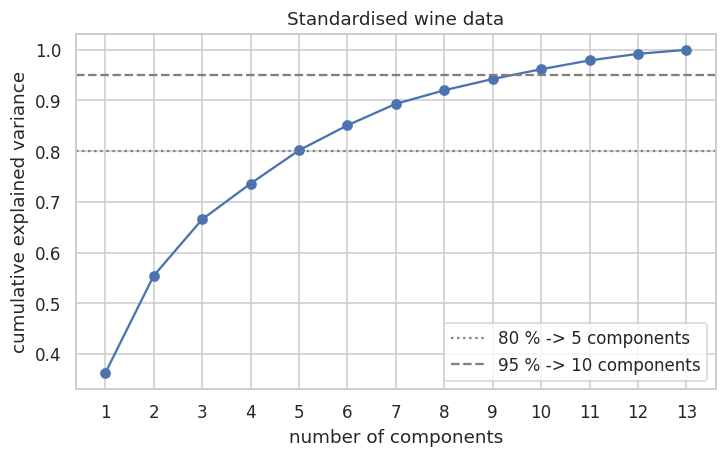

cumulative: [0.362  0.5541 0.6653 0.736  0.8016 0.851  0.8934 0.9202 0.9424 0.9617
 0.9791 0.992  1.    ]



(b) CV accuracy of scaler -> PCA -> logistic regression, by n_components:
 n_components  cv_accuracy  cv_std
            1       0.8424  0.0688
            2       0.9606  0.0285
            3       0.9605  0.0337
            4       0.9659  0.0333
            5       0.9717  0.0359
            6       0.9662  0.0326
            7       0.9719  0.0304
            8       0.9719  0.0304
            9       0.9775  0.0209
           10       0.9775  0.0209
           11       0.9775  0.0209
           12       0.9832  0.0223
           13       0.9832  0.0223

(c) loadings of standardised component 2 (largest first):
color_intensity                 0.5300
alcohol                         0.4840
proline                         0.3650
ash                             0.3160
magnesium                       0.3000
hue                            -0.2790
malic_acid                      0.2250
od280/od315_of_diluted_wines   -0.1640
total_phenols                   0.0650
proanthocyanins          

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# (a) what the first unstandardised component is made of
_pca_raw = PCA(random_state=SEED).fit(_X_wine)
_load_raw = pd.Series(_pca_raw.components_[0], index=_features)
print("(a) first unstandardised component, largest absolute loadings:")
print(_load_raw.abs().sort_values(ascending=False).head(3).round(5).to_string())
print("variance of each raw column, top three:")
print(wine[_features].var().sort_values(ascending=False).head(3).round(2).to_string())
print(f"share of total raw variance that is proline's: "
      f"{wine['proline'].var() / wine[_features].var().sum():.4f}")

# (b) the curve, and a choice made by the task
fig, ax = plt.subplots(figsize=(7.5, 4.2))
_cum = _scaled_result["cumulative"]
ax.plot(range(1, 14), _cum, marker="o")
for t, style in ((0.8, ":"), (0.95, "--")):
    ax.axhline(t, color="grey", linestyle=style, label=f"{int(t * 100)} % -> {_scaled_result['needed'][t]} components")
ax.set_xlabel("number of components")
ax.set_ylabel("cumulative explained variance")
ax.set_title("Standardised wine data")
ax.set_xticks(range(1, 14))
ax.legend()
plt.show()
print("cumulative:", _cum.round(4))

_pca_pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(random_state=SEED)),
                      ("clf", LogisticRegression(max_iter=1000, random_state=SEED))])
_search_pca = GridSearchCV(_pca_pipe, {"pca__n_components": list(range(1, 14))},
                           cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="accuracy")
_search_pca.fit(wine[_features].values, wine["target"].values)
_res = pd.DataFrame({"n_components": _search_pca.cv_results_["param_pca__n_components"].astype(int),
                     "cv_accuracy": _search_pca.cv_results_["mean_test_score"],
                     "cv_std": _search_pca.cv_results_["std_test_score"]})
print("\n(b) CV accuracy of scaler -> PCA -> logistic regression, by n_components:")
print(_res.round(4).to_string(index=False))

# (c) what "component 2" is
_pca3 = PCA(n_components=3, random_state=SEED).fit(StandardScaler().fit_transform(_X_wine))
_load2 = pd.Series(_pca3.components_[1], index=_features).sort_values(key=np.abs, ascending=False)
print("\n(c) loadings of standardised component 2 (largest first):")
print(_load2.round(3).to_string())

**Your answer:**

**(a)** Перша нестандартизована компонента практично збігається з `proline`: навантаження 0,9998, наступні `magnesium` 0,0179 і `alcalinity_of_ash` 0,0047. Дисперсія `proline` у вихідних одиницях дорівнює 99 166,72 проти 203,99 у `magnesium`, тобто `proline` дає 99,77 % сумарної дисперсії всіх 13 стовпців. PCA шукає напрям найбільшої дисперсії у тих одиницях, які їй дали, тож вона «знайшла» стовпець із найбільшими числами. Це твердження про одиниці вимірювання, а не про хімію вина: якби `proline` записали в одиницях, у тисячу разів більших, він би зник із першої компоненти. Тому PCA на стовпцях у різних одиницях без стандартизації позбавлена змісту. Після стандартизації перша компонента пояснює вже 36,20 %.

**(b)** Кумулятивна крива для стандартизованих даних досягає 80 % на п'ятій компоненті (0,8016) і 95 % на десятій (0,9617), але обидва пороги довільні. Процедура, прив'язана до задачі, така: вставити PCA в `Pipeline` між `StandardScaler` і моделлю, вважати `n_components` гіперпараметром і вибирати його за перехресною перевіркою на тренувальних даних (Practice 3 §6.5), а тестову частину використати один раз наприкінці. Я зробив це з логістичною регресією: точність зростає з 0,8424 для однієї компоненти до 0,9606 для двох, далі приріст не перевищує 2,3 пункту (0,9832 для 12–13 компонент), і він порівнянний із розкидом між фолдами (0,02–0,03). Якщо брати найменшу кількість компонент, точність якої лежить у межах одного стандартного відхилення від найкращої, виходить 4 компоненти (0,9659), тобто менше, ніж за правилом 80 % (5 компонент), і в 2,5 раза менше, ніж за правилом 95 % (10 компонент).

**(c)** Сказати можна таке: модель спирається на напрям у просторі стандартизованих ознак, який є зваженою сумою всіх 13 вимірювань. За моїми навантаженнями друга компонента зростає разом з `color_intensity` (0,530), `alcohol` (0,484), `proline` (0,365), `ash` (0,316), `magnesium` (0,300) і спадає з `hue` (−0,279). Тому винороб почує, що сорти розрізняє поєднання інтенсивнішого кольору, вищого вмісту алкоголю та проліну і нижчого відтінку. Сказати не можна, що якесь одне вимірювання є найсильнішим предиктором, бо «компонента 2» не є вимірюванням. Не можна давати коефіцієнт у фізичних одиницях, бо компонента виміряна в стандартних відхиленнях саме цих 178 вин, а для самих ознак набір не має одиниць. Не можна робити причинних висновків на кшталт «змініть X, і вино стане іншим сортом». Знак компоненти довільний (PCA може його перевернути), а на інших даних друга компонента була б іншою комбінацією.

## 11. Task 10 — A two-dimensional projection of 784 dimensions

Applied, and the last mechanical task. This is the projection Lesson 3
clusters.

`mnist_sample.csv` is 1500 handwritten digits, each a 28 by 28 image
flattened into 784 pixel columns. Reducing with PCA before running t-SNE
is standard practice: it removes noise and makes t-SNE several times
faster.

*see Practice 2 §15.2, §15.5 and §15.6*

In [28]:
from sklearn.manifold import TSNE

def project_two_ways(X, perplexity, seed, n_pca=50):
    """Project a high-dimensional array to 2-D, twice, and compare.

    Steps, in this order:
      1. standardise X with StandardScaler
      2. PCA to `n_pca` components, random_state=seed  -> the t-SNE input
      3. t-SNE from that reduction to 2 components, with the given
         `perplexity`, random_state=seed and init='pca'

    Separately, take the first TWO components of a PCA on the standardised
    data, so the linear and nonlinear projections can be compared.

    Return a dict with exactly these four keys:
        'pca_2d'        shape (n_samples, 2), the linear projection
        'tsne_2d'       shape (n_samples, 2), the nonlinear projection
        'explained_2d'  the fraction of variance the two PCA components
                        carry, a float between 0 and 1
        'reduced'       shape (n_samples, n_pca), the PCA input to t-SNE
    """
    scaled = StandardScaler().fit_transform(X.astype(float))
    reduced = PCA(n_components=n_pca, random_state=seed).fit_transform(scaled)
    tsne_2d = TSNE(n_components=2, perplexity=perplexity, random_state=seed,
                   init="pca").fit_transform(reduced)
    pca_two = PCA(n_components=2, random_state=seed).fit(scaled)
    return {
        "pca_2d": pca_two.transform(scaled),
        "tsne_2d": tsne_2d,
        "explained_2d": float(pca_two.explained_variance_ratio_.sum()),
        "reduced": reduced,
    }

In [29]:
mnist = pd.read_csv(
    "https://raw.githubusercontent.com/djnzx/ida-practice-3d/main/practice/datasets/mnist_sample.csv"
)
digit_labels = mnist["label"].values
pixels = mnist.drop(columns="label").values

print("pixels", pixels.shape, " labels", digit_labels.shape)
print("one row reshaped back into an image:", pixels[0].reshape(28, 28).shape)

# A 300-row subset keeps the assert cell below to a few seconds.
_small = pixels[:300]
_projection = project_two_ways(_small, perplexity=30, seed=SEED)

pixels (1500, 784)  labels (1500,)
one row reshaped back into an image: (28, 28)


In [30]:
# LOCAL ALTERNATIVE. Run EITHER this cell OR the one above, not both.
# Above reads over the network and is what Colab needs. This one reads
# the same files from your checkout, for the dev-env container. The
# data is identical; only the address differs.
# Not run here: the data was read over the network by the cell above,
# so this cell is kept commented out to make Restart and run all work.
# mnist = pd.read_csv("../datasets/mnist_sample.csv")
# digit_labels = mnist["label"].values
# pixels = mnist.drop(columns="label").values
#
# print("pixels", pixels.shape, " labels", digit_labels.shape)
# print("one row reshaped back into an image:", pixels[0].reshape(28, 28).shape)
#
# # A 300-row subset keeps the assert cell below to a few seconds.
# _small = pixels[:300]
# _projection = project_two_ways(_small, perplexity=30, seed=SEED)

In [31]:
assert set(_projection) == {"pca_2d", "tsne_2d", "explained_2d", "reduced"}
assert _projection["pca_2d"].shape == (300, 2), f"pca_2d shape {_projection['pca_2d'].shape}"
assert _projection["tsne_2d"].shape == (300, 2), f"tsne_2d shape {_projection['tsne_2d'].shape}"
assert _projection["reduced"].shape == (300, 50), f"reduced shape {_projection['reduced'].shape}"
assert 0.0 < _projection["explained_2d"] < 1.0

# Two linear components cannot carry much of 784 dimensions.
assert _projection["explained_2d"] < 0.30, \
    f"two components explaining {_projection['explained_2d']:.1%} of 784 dimensions looks wrong"

# Seeded, so the same call reproduces exactly...
_again = project_two_ways(_small, perplexity=30, seed=SEED)
assert np.allclose(_projection["tsne_2d"], _again["tsne_2d"]), \
    "same seed must give the same embedding; did you pass random_state?"

# ...and a different seed does not.
_other = project_two_ways(_small, perplexity=30, seed=SEED + 1)
assert not np.allclose(_projection["tsne_2d"], _other["tsne_2d"]), \
    "a different seed should give a different embedding"

# t-SNE is not PCA: the two projections must differ.
assert not np.allclose(_projection["pca_2d"], _projection["tsne_2d"])

# t-SNE places THESE points and has no rule for placing new ones. Ask the
# class, not an instance -- there is nothing to seed and nothing to fit.
assert not hasattr(TSNE, "transform"), \
    "t-SNE has no transform, which is why it cannot be a preprocessing step"
assert hasattr(PCA, "transform"), "PCA does have one, and that is the difference"

print(f"two PCA components carry {_projection['explained_2d']:.2%} of the variance")
print("Task 10 passed.")

two PCA components carry 13.58% of the variance
Task 10 passed.


### Question 7 — perplexity, and the seed

Using the **full** 1500 rows this time, produce three t-SNE projections at
`perplexity` = 5, 30 and 50, all with the same seed, and draw them side by
side coloured by `digit_labels`. Then produce two more at `perplexity=30`
with two **different** seeds.

**(a)** Describe how the picture changes across the three perplexities.
Roughly what is perplexity controlling — say it in terms of how many
neighbours each point is trying to stay close to. Which extreme shatters
the classes and which merges them?

**(b)** Your two different-seed runs at the same perplexity also differ.
Explain why t-SNE is seed-dependent at all, and what that means for a
figure published without a stated `random_state`.

**(c)** Compare any of your t-SNE panels with the `pca_2d` projection. The
t-SNE picture separates the digits far better. State **three things you
still cannot conclude** from it — refer to Practice 2 §15.7 — and say which
of the two projections you would use as input to a clustering algorithm,
and why.

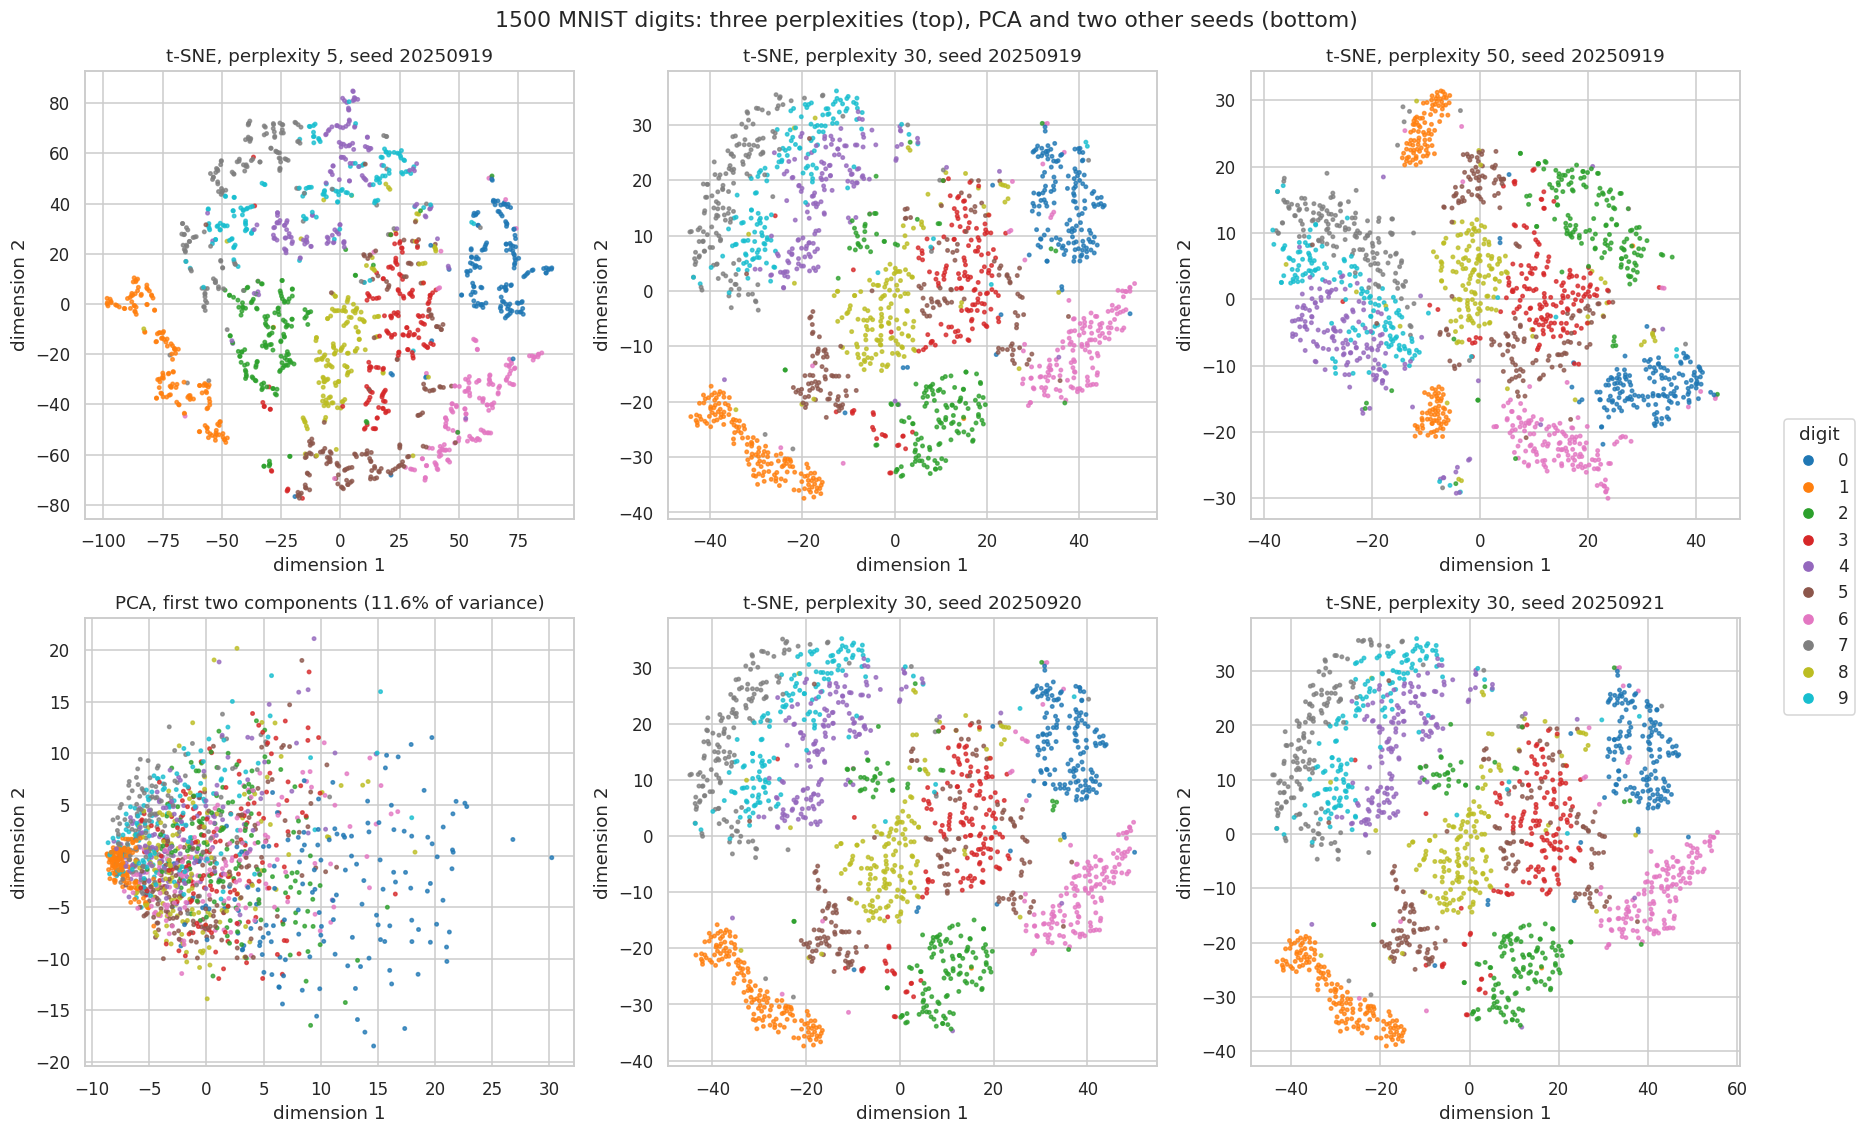

embedding                   5-NN accuracy  silhouette by true digit   x-range
t-SNE p=5                          0.8673                    0.1667     187.5
t-SNE p=30                         0.8787                    0.2020      96.4
t-SNE p=50                         0.8793                    0.1543      82.4


t-SNE p=30 seed 20250920           0.8787                    0.1998      94.9
t-SNE p=30 seed 20250921           0.8800                    0.2057      99.8
PCA 2-D                            0.3007                   -0.0917      38.9
PCA 50-D (t-SNE input)             0.8813                    0.0103      38.9

seed 20250919 vs seed 20250920: coordinates identical? False; largest shift of a point 35.89; correlation of x-coordinates +0.998


init='random', seeds 20250920 and 20250921: correlation of x-coordinates +0.517, of y-coordinates -0.130
    seed 20250920: 5-NN accuracy 0.8820
    seed 20250921: 5-NN accuracy 0.8787


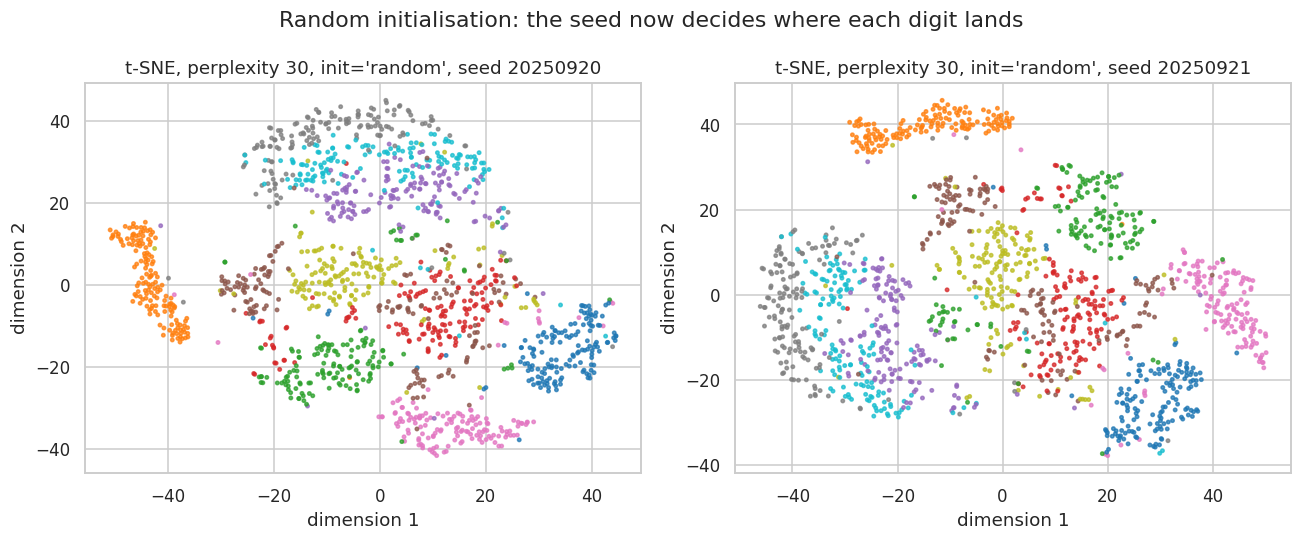

In [32]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import silhouette_score

_full = project_two_ways(pixels, perplexity=30, seed=SEED)
_tsne = {30: _full["tsne_2d"]}
for p in (5, 50):
    _tsne[p] = TSNE(n_components=2, perplexity=p, random_state=SEED, init="pca").fit_transform(_full["reduced"])
_seed_runs = {s: project_two_ways(pixels, perplexity=30, seed=s)["tsne_2d"] for s in (SEED + 1, SEED + 2)}

def _panel(ax, xy, title):
    ax.scatter(xy[:, 0], xy[:, 1], c=digit_labels, cmap="tab10", s=5, alpha=0.75)
    ax.set_title(title)
    ax.set_xlabel("dimension 1")
    ax.set_ylabel("dimension 2")

fig, axes = plt.subplots(2, 3, figsize=(17, 10.5))
for ax, p in zip(axes[0], (5, 30, 50)):
    _panel(ax, _tsne[p], f"t-SNE, perplexity {p}, seed {SEED}")
_panel(axes[1, 0], _full["pca_2d"], f"PCA, first two components ({_full['explained_2d']:.1%} of variance)")
for ax, (s, xy) in zip(axes[1, 1:], _seed_runs.items()):
    _panel(ax, xy, f"t-SNE, perplexity 30, seed {s}")
_handles = [plt.Line2D([], [], marker="o", linestyle="", color=plt.cm.tab10(d / 9), label=str(d)) for d in range(10)]
fig.legend(handles=_handles, title="digit", loc="center right")
fig.suptitle("1500 MNIST digits: three perplexities (top), PCA and two other seeds (bottom)")
fig.tight_layout(rect=(0, 0, 0.95, 1))
plt.show()

# How well does each 2-D picture keep same-digit points together?
_cv_emb = StratifiedKFold(5, shuffle=True, random_state=SEED)
_embeddings = {f"t-SNE p={p}": _tsne[p] for p in (5, 30, 50)}
_embeddings.update({f"t-SNE p=30 seed {s}": xy for s, xy in _seed_runs.items()})
_embeddings["PCA 2-D"] = _full["pca_2d"]
_embeddings["PCA 50-D (t-SNE input)"] = _full["reduced"]
print(f"{'embedding':26} {'5-NN accuracy':>14} {'silhouette by true digit':>25} {'x-range':>9}")
for name, xy in _embeddings.items():
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=5), xy, digit_labels, cv=_cv_emb).mean()
    sil = silhouette_score(xy, digit_labels)
    print(f"{name:26} {acc:>14.4f} {sil:>25.4f} {np.ptp(xy[:, 0]):>9.1f}")

# Same perplexity, different seed: how far does a point move?
_a, _b = _tsne[30], _seed_runs[SEED + 1]
print(f"\nseed {SEED} vs seed {SEED + 1}: coordinates identical? {np.allclose(_a, _b)}; "
      f"largest shift of a point {np.max(np.linalg.norm(_a - _b, axis=1)):.2f}; "
      f"correlation of x-coordinates {np.corrcoef(_a[:, 0], _b[:, 0])[0, 1]:+.3f}")

# init='pca' starts every run from the same PCA layout, so the seed only enters
# through the randomised PCA solver. With init='random' the seed sets the whole start.
_random_init = {s: TSNE(n_components=2, perplexity=30, random_state=s, init="random").fit_transform(_full["reduced"])
                for s in (SEED + 1, SEED + 2)}
_ra, _rb = _random_init.values()
print(f"init='random', seeds {SEED + 1} and {SEED + 2}: correlation of x-coordinates "
      f"{np.corrcoef(_ra[:, 0], _rb[:, 0])[0, 1]:+.3f}, of y-coordinates {np.corrcoef(_ra[:, 1], _rb[:, 1])[0, 1]:+.3f}")
for s, xy in _random_init.items():
    acc = cross_val_score(KNeighborsClassifier(n_neighbors=5), xy, digit_labels, cv=_cv_emb).mean()
    print(f"    seed {s}: 5-NN accuracy {acc:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (s, xy) in zip(axes, _random_init.items()):
    _panel(ax, xy, f"t-SNE, perplexity 30, init='random', seed {s}")
fig.suptitle("Random initialisation: the seed now decides where each digit lands")
fig.tight_layout()
plt.show()

**Your answer:**

**(a)** При perplexity 5 цифри розпадаються на багато дрібних фрагментів (одиниці, наприклад, утворюють кілька окремих острівців), і картина розтягнута (розмах першої осі 187,5). При 30 кожна цифра утворює компактний острів, а близькі за написанням 4, 7 і 9 сусідять. При 50 цифри 4, 7 і 9 зливаються в одну суцільну область, межі між сусідніми групами розмиваються, а розмах осі зменшується до 82,4; окремі цифри (0, 6) лишаються компактними, а одиниці навіть розділилися на дві частини. Perplexity приблизно задає, скільки найближчих сусідів кожна точка намагається втримати поруч, тобто розмір околиці, за якою визначається схожість. Мале значення розбиває класи, бо кожна точка зважає лише на п'ять сусідів і дрібні групи стають окремими островами, велике зливає класи, бо в околицю потрапляють точки інших цифр. За числами найкомпактніші групи цифр дає середнє значення: силует за справжніми мітками 0,1667, 0,2020 і 0,1543 для 5, 30 і 50, тоді як точність 5-NN у площині майже однакова (0,8673, 0,8787, 0,8793). Жодна з трьох картин не є «правдивішою» (Practice 2 §15.8).

**(b)** З `init='pca'` два інші seed при perplexity 30 дали майже ту саму картину (кореляція x-координат +0,998), але не ідентичну: окремі точки зсунулися аж на 35,9 одиниці. У цьому режимі seed впливає лише через рандомізований PCA, яким будується початкова конфігурація і 50-вимірний вхід. З `init='random'` різниця принципова: для двох seed кореляція x-координат лише +0,517, а y-координат −0,130, тобто острови розташовані інакше (повернуті, віддзеркалені, переставлені), хоча якість сусідства однакова (5-NN 0,8820 і 0,8787). t-SNE залежить від seed, бо мінімізує неопуклу функцію (розбіжність Кульбака–Лейблера) градієнтним спуском із випадкового старту, і різні старти приводять до різних локальних мінімумів. Крім того, функція не змінюється при поворотах і відображеннях, тож єдиного розв'язку немає. Рисунок без зазначеного `random_state` (а також `init` і `perplexity`) неможливо відтворити, і взаємне розташування островів на ньому є лише одним із багатьох рівноцінних результатів, тому робити висновки з позицій не можна.

**(c)** Дві компоненти PCA несуть лише 11,6 % дисперсії 1500 зображень (13,58 % на підвибірці з 300), цифри в цій площині сильно перекриваються: точність 5-NN 0,3007 і силует −0,09 проти 0,88 і 0,20 у t-SNE. Водночас 50-вимірна PCA, яка є входом t-SNE, уже дає 5-NN 0,8813, тож t-SNE не створює роздільності, а лише робить видимою у двох вимірах сусідську структуру, яка вже є в даних. Відповідно до Practice 2 §15.7 з картинки t-SNE не можна зробити трьох висновків: осі не мають змісту і одиниць; відстані між островами не означають ступеня відмінності (те, що острів нулів далеко від острова одиниць, не робить їх найбільш несхожими); розміри та щільність островів не означають більшої чи меншої мінливості класу. До того ж t-SNE не має `transform` і не може розмістити нове зображення. Як вхід для кластеризації я взяв би лінійну проєкцію PCA (на практиці 50 компонент, а з двох запропонованих `pca_2d`), бо відстані в ній є лінійною функцією відстаней між стандартизованими зображеннями, вона відтворювана і застосовна до нових даних. Алгоритм на основі відстаней, запущений на координатах t-SNE, вимірював би артефакти оптимізації (Practice 3 §13.5).

## 12. Task 11 — A figure that answers a stated question

Applied. The question: **does the daily demand profile for bicycles differ
between working days and non-working days, and how does weather change
it?**

*see Practice 2 §8.4, §9 and §10*

In [33]:
def demand_profile_figure(bikes_frame):
    """Draw a two-panel figure answering the question above. Return (fig, axes).

    Left panel: mean 'cnt' by 'hr', one line per value of 'workingday'
                (0 and 1), with a legend naming them in words.
    Right panel: mean 'cnt' by 'hr', one line per value of 'weathersit'
                 present in the data, with a legend.

    Both panels need an x label, a y label and a title. The figure needs a
    suptitle. Use the object-oriented interface.
    """
    day_names = {0: "non-working day (weekend or holiday)", 1: "working day"}
    weather_names = {1: "1 clear, partly cloudy", 2: "2 mist, cloudy",
                     3: "3 light rain or snow", 4: "4 heavy rain, ice, fog"}

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)

    by_day = bikes_frame.groupby(["hr", "workingday"])["cnt"].mean().unstack("workingday")
    for code, marker in zip(by_day.columns, ("o", "s")):
        axes[0].plot(by_day.index, by_day[code], marker=marker, markersize=4, label=day_names[code])
    axes[0].set_title("Working days against non-working days")

    by_weather = bikes_frame.groupby(["hr", "weathersit"])["cnt"].mean().unstack("weathersit")
    hours_per_weather = bikes_frame["weathersit"].value_counts()
    for code in by_weather.columns:
        line = by_weather[code].dropna()
        sparse = hours_per_weather[code] < 100     # too few hours to join into a profile
        axes[1].plot(line.index, line.values, marker="X" if sparse else "o",
                     markersize=9 if sparse else 4, linestyle="none" if sparse else "-",
                     label=f"{weather_names[code]} ({hours_per_weather[code]:,} hours)")
    axes[1].set_title("By weather situation, all days pooled")

    for ax in axes:
        ax.set_xlabel("hour of day")
        ax.set_xticks(range(0, 24, 2))
        ax.legend(fontsize=9)
    axes[0].set_ylabel("mean rentals per hour (cnt)")
    axes[1].set_ylabel("mean rentals per hour (cnt)")
    fig.suptitle("Hourly bicycle demand, Washington D.C. 2011-2012")
    fig.tight_layout()
    return fig, axes

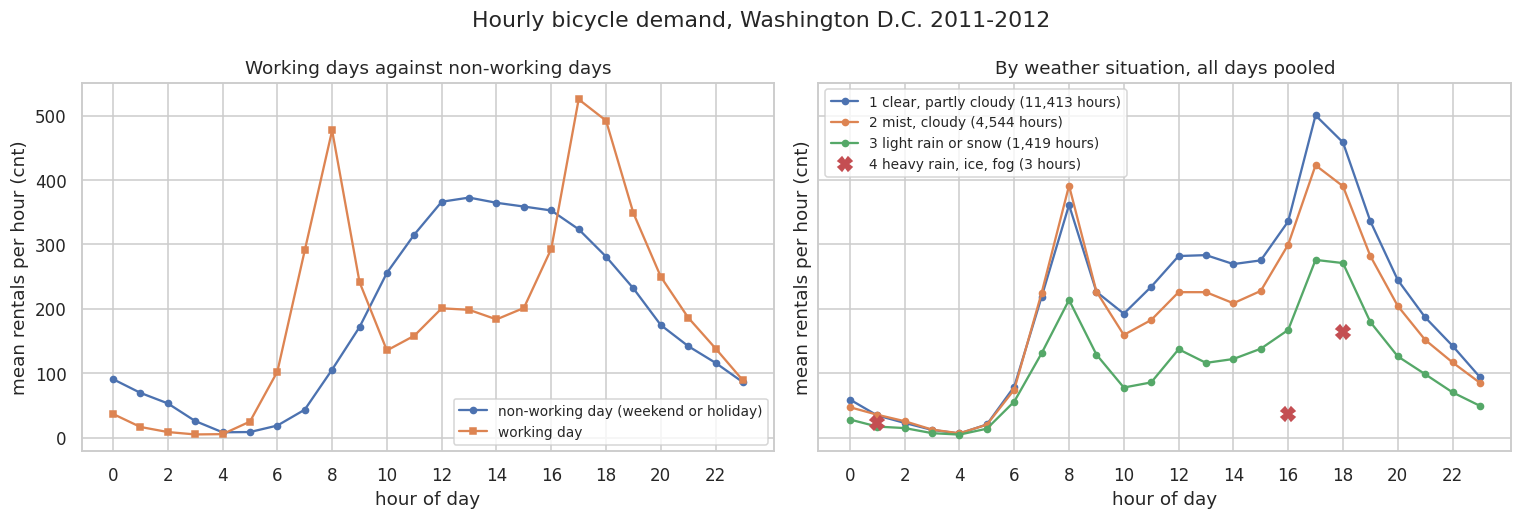

Task 11 passed.


In [34]:
_fig, _axes = demand_profile_figure(bikes)

assert len(_axes) == 2, f"expected two panels, got {len(_axes)}"
for _i, _ax in enumerate(_axes):
    assert _ax.get_xlabel(), f"panel {_i} has no x label"
    assert _ax.get_ylabel(), f"panel {_i} has no y label"
    assert _ax.get_title(), f"panel {_i} has no title"
    assert _ax.get_legend() is not None, f"panel {_i} has no legend"
    assert len(_ax.lines) >= 2, f"panel {_i} should have at least two lines"
assert _fig._suptitle is not None and _fig._suptitle.get_text(), "the figure has no suptitle"
assert len(_axes[0].lines) == 2, "the left panel compares exactly two groups"

plt.show()
print("Task 11 passed.")

### Question 8 — pooling and conditioning

**(a)** Draw the *pooled* profile as well: mean `cnt` by `hr` with no
conditioning. Compare it with your two-line left panel. Describe a
statement about commuter behaviour that the pooled figure would support
and that is false for both of the underlying groups.

**(b)** This is the same phenomenon as Practice 2 §12. Name it, and state
the general rule it implies about reporting an aggregate.

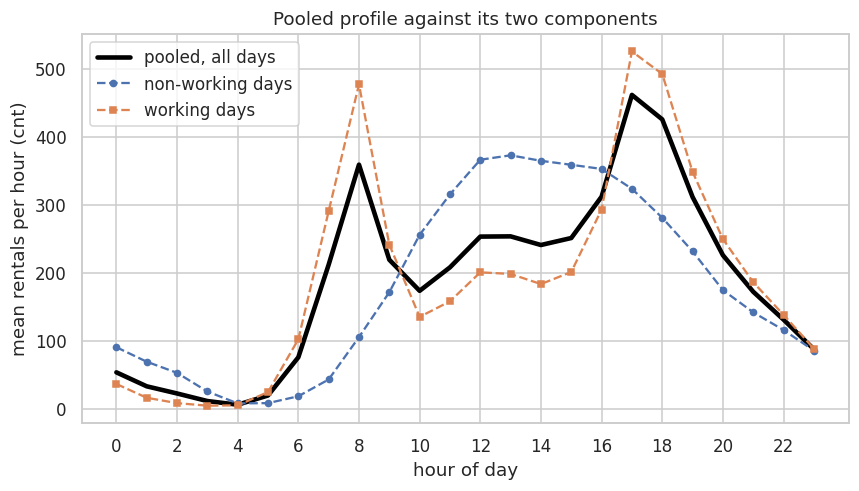

     pooled  non-working  working
hr                               
7  212.1000      43.4000 290.6000
8  359.0000     105.7000 477.0000
9  219.3000     171.6000 241.5000
12 253.3000     366.3000 200.8000
13 253.7000     372.7000 198.4000
14 240.9000     364.6000 183.6000
17 461.5000     323.5000 525.3000
18 425.5000     281.1000 492.2000

share of hours that are working-day hours: 0.6827
pooled      : 08:00 / 13:00 = 1.42;  peak hour 17; 13:00 as a share of the 17:00 value 0.55
non-working : 08:00 / 13:00 = 0.28;  peak hour 13; 13:00 as a share of the 17:00 value 1.15
working     : 08:00 / 13:00 = 2.40;  peak hour 17; 13:00 as a share of the 17:00 value 0.38


In [35]:
_pooled = bikes.groupby("hr")["cnt"].mean()
_by_day = bikes.groupby(["hr", "workingday"])["cnt"].mean().unstack("workingday")

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(_pooled.index, _pooled.values, color="black", linewidth=3, label="pooled, all days")
ax.plot(_by_day.index, _by_day[0], marker="o", markersize=4, linestyle="--", label="non-working days")
ax.plot(_by_day.index, _by_day[1], marker="s", markersize=4, linestyle="--", label="working days")
ax.set_xlabel("hour of day")
ax.set_ylabel("mean rentals per hour (cnt)")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Pooled profile against its two components")
ax.legend()
plt.show()

_tab = pd.DataFrame({"pooled": _pooled, "non-working": _by_day[0], "working": _by_day[1]})
print(_tab.loc[[7, 8, 9, 12, 13, 14, 17, 18]].round(1).to_string())
print(f"\nshare of hours that are working-day hours: {bikes['workingday'].mean():.4f}")
for name, col in (("pooled", _pooled), ("non-working", _by_day[0]), ("working", _by_day[1])):
    print(f"{name:12}: 08:00 / 13:00 = {col[8] / col[13]:.2f};  peak hour {int(col.idxmax())}; "
          f"13:00 as a share of the 17:00 value {col[13] / col[17]:.2f}")

**Your answer:**

**(a)** Об'єднаний профіль має пік о 8:00 (359,0 поїздки), більший пік о 17:00 (461,5) і денне плато близько 253 поїздок о 12:00–13:00. Він підтримує твердження: «у типовий день є чіткий ранковий пік о 8:00, приблизно в 1,4 раза вищий за денний рівень, а вдень попит тримається близько 250 поїздок на годину, тобто приблизно на половині вечірнього піку». Для жодної з груп це неправда. У робочі дні ранковий пік у 2,4 раза вищий за обідній (477,0 проти 198,4), а о 13:00 попит становить лише 38 % від рівня 17:00. У неробочі дні ранкового піку немає взагалі: о 8:00 лише 105,7 поїздки, 0,28 обіднього рівня, а година 13:00 (372,7) є максимумом доби і навіть на 15 % перевищує 17:00. Денний рівень близько 250 теж не описує жодну групу (≈ 200 у робочі дні, ≈ 370 у неробочі). Об'єднана крива є зваженим середнім із вагою 68,3 % робочих годин, тому формою вона нагадує робочі дні, але з притупленими піками і завищеним обідом.

**(b)** Це парадокс Сімпсона, тобто спотворення через агрегування за змінною, яка змінює відповідь (Practice 2 §12, а для цих даних §8.4): обумовлення на `workingday` дає дві зовсім різні форми, а усереднення по ній ховає це. Загальне правило таке: перш ніж повідомляти агрегат, треба перевірити, чи немає змінної, що ділить сукупність на групи з різною поведінкою, і якщо є, звітувати про результати в групах разом із їхніми частками. Агрегат описує суміш, і його форма залежить від пропорцій суміші. Рік з іншою кількістю вихідних дав би інший об'єднаний профіль навіть без жодної зміни в поведінці велосипедистів.

## 13. Task 12 — Open-ended

No assert. Marked on the written analysis.

`bike_sharing_hourly.csv` is documented in `practice/datasets/README.md`.
Read that table first: four of the columns are integer-coded categories,
four are physical measurements that the publisher divided by a constant,
one is a date stored as text, and `casual + registered` equals `cnt`
exactly.

**Produce a short data-quality and structure report on this table.** Cover
at least:

1. **Types.** Which columns does pandas infer wrongly, in the sense that
   the inferred type permits an operation that is meaningless? Fix them
   and show one operation that becomes an error after your fix.
2. **Units.** Restore the four normalised columns to physical units and
   sanity-check the resulting ranges against what you know about
   Washington D.C. Report anything that looks wrong.
3. **The date.** Parse `dteday`. Confirm the series is complete: is there
   one row for every hour of every day in the range? If rows are missing,
   how many, and does their absence look random?
4. **A correlation you should not compute.** Produce the correlation
   matrix of the numeric columns, then identify at least two entries in it
   that are meaningless or misleading, and say why. At least one of your
   examples must be about an integer-coded category.
5. **Leakage.** Explain why `casual` and `registered` must not be used as
   features to predict `cnt`. Then describe a realistic prediction task
   for this dataset in which using them *would* be legitimate.
6. **A recommendation.** In one paragraph: which columns would you hand to
   a model that predicts hourly demand, and which would you exclude and
   why. Practice 3 §4 fits that model, so this is a real handover.

A good answer distinguishes "wrong" from "misleading" and says which of
its findings would actually change a modelling decision.

In [36]:
# 1. Types as pandas inferred them
print(bikes.dtypes.to_string())
print()
print("distinct values:", bikes.nunique().to_dict())
print()
print("operations the inferred types allow but that mean nothing:")
print(f"  mean season  = {bikes['season'].mean():.4f}   (between 'summer' and 'fall'?)")
print(f"  mean weekday = {bikes['weekday'].mean():.4f}")
print(f"  hr 23 - hr 0 = {23 - 0} hours apart, although the two hours are adjacent")
print(f"  max dteday   = {bikes['dteday'].max()!r}  (a string comparison, works only because of the ISO format)")

instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
hr              int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64

distinct values: {'instant': 17379, 'dteday': 731, 'season': 4, 'yr': 2, 'mnth': 12, 'hr': 24, 'holiday': 2, 'weekday': 7, 'workingday': 2, 'weathersit': 4, 'temp': 50, 'atemp': 65, 'hum': 89, 'windspeed': 30, 'casual': 322, 'registered': 776, 'cnt': 869}

operations the inferred types allow but that mean nothing:
  mean season  = 2.5016   (between 'summer' and 'fall'?)
  mean weekday = 3.0037
  hr 23 - hr 0 = 23 hours apart, although the two hours are adjacent
  max dteday   = '2012-12-31'  (a string comparison, works only because of the ISO format)


In [37]:
# Fix the types on a copy
typed = bikes.copy()
typed["dteday"] = pd.to_datetime(typed["dteday"], format="%Y-%m-%d")
# Before naming the season codes, check them against the months and the temperature.
print(pd.crosstab(bikes["mnth"], bikes["season"]).to_string())
_first_days = bikes.groupby("dteday")["season"].first()
print("dates on which the code changes:", list(_first_days[_first_days.diff() != 0].index[1:5]))
print("mean temperature by season code, C:", (bikes.groupby("season")["temp"].mean() * 41).round(1).to_dict())
# Code 1 runs from 21 December to 20 March and is the coldest: the codes follow the
# astronomical seasons starting with winter, not the labels in the readme.
season_names = {1: "winter", 2: "spring", 3: "summer", 4: "autumn"}
typed["season"] = pd.Categorical(typed["season"].map(season_names),
                                 categories=["winter", "spring", "summer", "autumn"])
for col in ("mnth", "hr", "weekday"):
    typed[col] = pd.Categorical(typed[col])                       # labels, not quantities
typed["weathersit"] = pd.Categorical(typed["weathersit"], categories=[1, 2, 3, 4], ordered=True)
typed["year"] = typed["yr"].map({0: 2011, 1: 2012})
for col in ("holiday", "workingday"):
    typed[col] = typed[col].astype(bool)
print(typed.dtypes.to_string())

print()
for label, op in (("typed['season'].mean()", lambda: typed["season"].mean()),
                  ("typed['hr'].mean()", lambda: typed["hr"].mean()),
                  ("typed['weathersit'].mean()", lambda: typed["weathersit"].mean())):
    try:
        print(label, "->", op())
    except TypeError as err:
        print(label, "-> TypeError:", err)
print("typed['weathersit'].max() ->", typed["weathersit"].max(), "(an ordered category still has a maximum)")
print("typed['dteday'].max() - typed['dteday'].min() ->", typed["dteday"].max() - typed["dteday"].min())

season     1     2     3     4
mnth                          
1       1429     0     0     0
2       1341     0     0     0
3        949   524     0     0
4          0  1437     0     0
5          0  1488     0     0
6          0   960   480     0
7          0     0  1488     0
8          0     0  1475     0
9          0     0  1053   384
10         0     0     0  1451
11         0     0     0  1437
12       523     0     0   960
dates on which the code changes: ['2011-03-21', '2011-06-21', '2011-09-23', '2011-12-21']
mean temperature by season code, C: {1: 12.3, 2: 22.3, 3: 29.0, 4: 17.3}
instant                int64
dteday        datetime64[ns]
season              category
yr                     int64
mnth                category
hr                  category
holiday                 bool
weekday             category
workingday              bool
weathersit          category
temp                 float64
atemp                float64
hum                  float64
windspeed            float

           temp_c     atemp_c     hum_pct    wind_kmh
count 17,379.0000 17,379.0000 17,379.0000 17,379.0000
mean      20.3800     23.7900     62.7200     12.7400
std        7.8900      8.5900     19.2900      8.2000
min        0.8200      0.0000      0.0000      0.0000
25%       13.9400     16.6600     48.0000      7.0000
50%       20.5000     24.2400     63.0000     13.0000
75%       27.0600     31.0600     78.0000     17.0000
max       41.0000     50.0000    100.0000     57.0000

hours with temperature below 0 C under the /41 rule: 0
coldest month by mean temp_c: 1 with mean 9.7 C

alternative min-max reading: temp -7.1 .. 39.0 C, hours below 0 C: 561;  atemp -16.0 .. 50.0 C

humidity exactly 0 %: 22 rows, dates ['2011-03-10'], weathersit there {3: 20, 2: 2}
wind speed exactly 0: 2180 rows (12.54%); smallest non-zero value 6.00 km/h; 30 distinct values in all
rows where temperature exceeds 'feels like' by more than 10 C: 24, dates ['2012-08-17']
          dteday hr  temp_c  atemp_c  

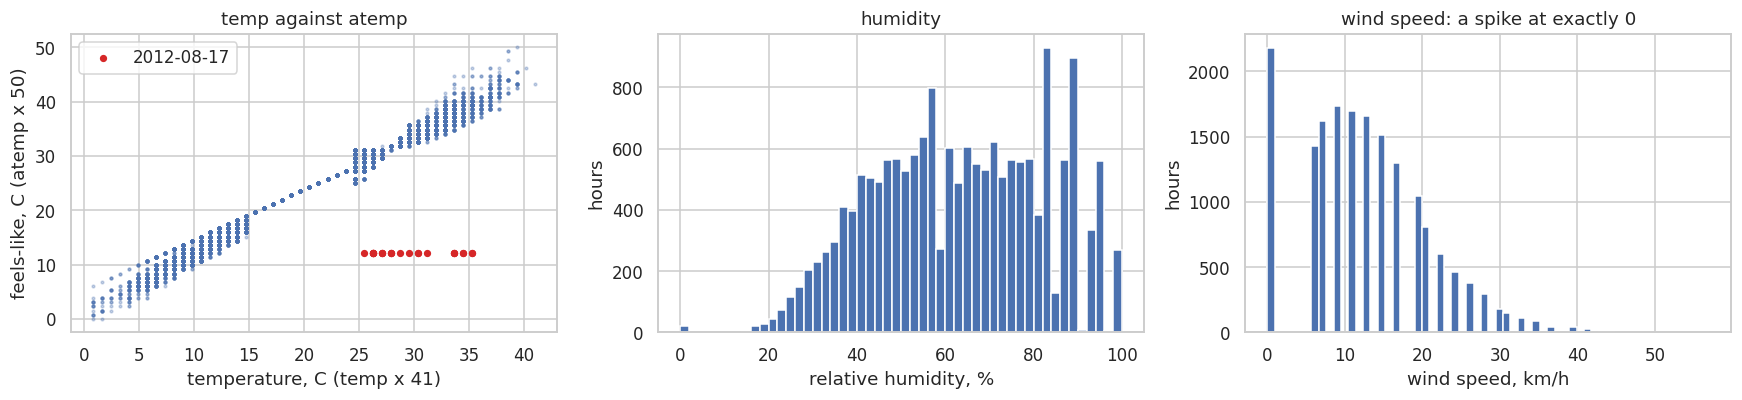

In [38]:
# 2. Units: undo the publisher's division, as documented in datasets/README.md
typed["temp_c"] = bikes["temp"] * 41
typed["atemp_c"] = bikes["atemp"] * 50
typed["hum_pct"] = bikes["hum"] * 100
typed["wind_kmh"] = bikes["windspeed"] * 67
print(typed[["temp_c", "atemp_c", "hum_pct", "wind_kmh"]].describe().round(2).to_string())

print("\nhours with temperature below 0 C under the /41 rule:", int((typed["temp_c"] < 0).sum()))
print("coldest month by mean temp_c:",
      typed.groupby("mnth", observed=True)["temp_c"].mean().round(1).idxmin(),
      "with mean", typed.groupby("mnth", observed=True)["temp_c"].mean().min().round(1), "C")

# UCI's own variable table documents a min-max scaling instead: t_min=-8, t_max=+39 for temp,
# t_min=-16, t_max=+50 for atemp.
_temp_minmax = -8 + 47 * bikes["temp"]
_atemp_minmax = -16 + 66 * bikes["atemp"]
print(f"\nalternative min-max reading: temp {_temp_minmax.min():.1f} .. {_temp_minmax.max():.1f} C, "
      f"hours below 0 C: {int((_temp_minmax < 0).sum())};  atemp {_atemp_minmax.min():.1f} .. {_atemp_minmax.max():.1f} C")

_zero_hum = typed[typed["hum_pct"] == 0]
print(f"\nhumidity exactly 0 %: {len(_zero_hum)} rows, dates {sorted(_zero_hum['dteday'].dt.date.astype(str).unique())}, "
      f"weathersit there {_zero_hum['weathersit'].astype(int).value_counts().to_dict()}")
_wind_values = np.sort(typed["wind_kmh"].unique())
print(f"wind speed exactly 0: {int((typed['wind_kmh'] == 0).sum())} rows ({(typed['wind_kmh'] == 0).mean():.2%}); "
      f"smallest non-zero value {_wind_values[1]:.2f} km/h; {len(_wind_values)} distinct values in all")
_gap = typed["temp_c"] - typed["atemp_c"]
_odd = typed[_gap > 10]
print(f"rows where temperature exceeds 'feels like' by more than 10 C: {len(_odd)}, "
      f"dates {sorted(_odd['dteday'].dt.date.astype(str).unique())}")
print(_odd[["dteday", "hr", "temp_c", "atemp_c", "hum_pct"]].head(4)
      .round({"temp_c": 2, "atemp_c": 2, "hum_pct": 2}).to_string())
print("distinct atemp values on that day:", typed.loc[typed["dteday"] == "2012-08-17", "atemp"].unique())

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].scatter(typed["temp_c"], typed["atemp_c"], s=3, alpha=0.3)
axes[0].scatter(_odd["temp_c"], _odd["atemp_c"], s=14, color="tab:red", label="2012-08-17")
axes[0].set_xlabel("temperature, C (temp x 41)")
axes[0].set_ylabel("feels-like, C (atemp x 50)")
axes[0].set_title("temp against atemp")
axes[0].legend()
axes[1].hist(typed["hum_pct"], bins=50)
axes[1].set_xlabel("relative humidity, %")
axes[1].set_ylabel("hours")
axes[1].set_title("humidity")
axes[2].hist(typed["wind_kmh"], bins=60)
axes[2].set_xlabel("wind speed, km/h")
axes[2].set_ylabel("hours")
axes[2].set_title("wind speed: a spike at exactly 0")
fig.tight_layout()
plt.show()

In [39]:
# 3. Is there one row per hour?
_start, _end = typed["dteday"].min(), typed["dteday"].max()
_expected_hours = pd.date_range(_start, _end + pd.Timedelta(hours=23), freq="h")
_stamps = typed["dteday"] + pd.to_timedelta(typed["hr"].astype(int), unit="h")
print(f"range {_start.date()} .. {_end.date()}: {typed['dteday'].nunique()} days, "
      f"expected {len(_expected_hours)} hourly rows, present {len(typed)}, duplicates {int(_stamps.duplicated().sum())}")
_missing = _expected_hours.difference(_stamps)
print(f"missing hours: {len(_missing)}")

_per_day = typed.groupby("dteday").size()
_short_days = _per_day[_per_day < 24]
print(f"days with fewer than 24 rows: {len(_short_days)}; days missing 1 hour: {(_short_days == 23).sum()}, "
      f"2 hours: {(_short_days == 22).sum()}, 3 or more: {(_short_days <= 21).sum()}")
print("days missing the most hours:")
print((24 - _short_days).sort_values(ascending=False).head(6).to_string())

_miss_hour = pd.Series(_missing.hour).value_counts().sort_index()
print("\nmissing hours by hour of day:", _miss_hour.to_dict())
_isolated = _missing[~_missing.normalize().isin(_short_days[_short_days < 18].index)]
print(f"missing hours outside the six worst days: {len(_isolated)}, of which between 01:00 and 05:59: "
      f"{int(((_isolated.hour >= 1) & (_isolated.hour <= 5)).sum())}")
print(f"\nsmallest cnt anywhere in the table: {typed['cnt'].min()}  (no row records an hour with zero rentals)")
print(f"mean cnt at 03:00-04:00 where present: {typed.loc[typed['hr'].astype(int).isin([3, 4]), 'cnt'].mean():.1f}; "
      f"share of those hours with cnt <= 3: {(typed.loc[typed['hr'].astype(int).isin([3, 4]), 'cnt'] <= 3).mean():.3f}")

range 2011-01-01 .. 2012-12-31: 731 days, expected 17544 hourly rows, present 17379, duplicates 0
missing hours: 165
days with fewer than 24 rows: 76; days missing 1 hour: 62, 2 hours: 6, 3 or more: 8
days missing the most hours:
dteday
2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
2011-08-28     7

missing hours by hour of day: {0: 5, 1: 7, 2: 16, 3: 34, 4: 34, 5: 14, 6: 6, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 3, 13: 2, 14: 2, 15: 2, 16: 1, 17: 1, 18: 3, 19: 3, 20: 3, 21: 3, 22: 3, 23: 3}
missing hours outside the six worst days: 86, of which between 01:00 and 05:59: 78

smallest cnt anywhere in the table: 1  (no row records an hour with zero rentals)
mean cnt at 03:00-04:00 where present: 9.0; share of those hours with cnt <= 3: 0.265


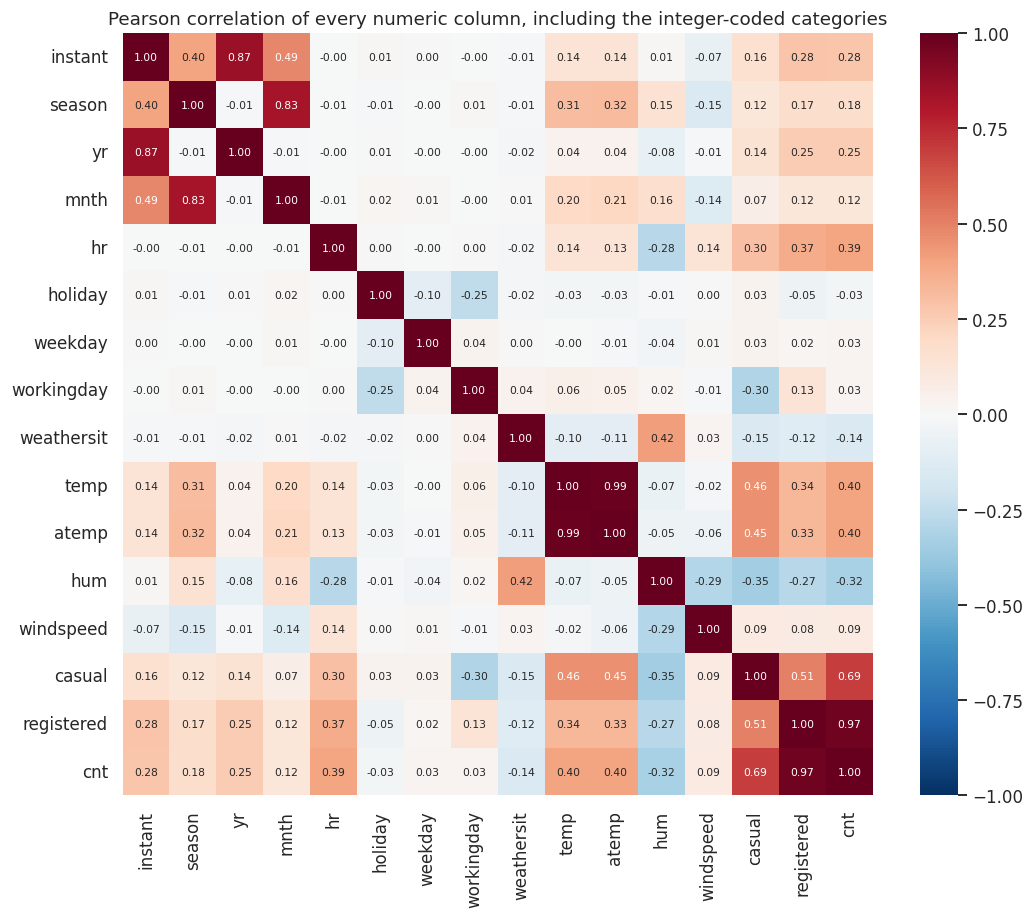

  r(cnt, hr) = +0.3941
  r(cnt, weekday) = +0.0269
  r(season, mnth) = +0.8304
  r(instant, yr) = +0.8660
  r(temp, atemp) = +0.9877
  r(cnt, registered) = +0.9722
  r(cnt, casual) = +0.6946

share of cnt variance explained by hour treated as a category (eta squared): 0.5015; r(cnt, hr) squared: 0.1553
r(cnt, weekday) with Sunday = 0: +0.0269;  with Sunday = 7: -0.0063


In [40]:
# 4. A correlation matrix of everything numeric, as pandas sees it
_numeric = bikes.select_dtypes("number")
_corr = _numeric.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Pearson correlation of every numeric column, including the integer-coded categories")
plt.show()

for a, b in (("cnt", "hr"), ("cnt", "weekday"), ("season", "mnth"), ("instant", "yr"),
             ("temp", "atemp"), ("cnt", "registered"), ("cnt", "casual")):
    print(f"  r({a}, {b}) = {_corr.loc[a, b]:+.4f}")

_mean_by_hr = bikes.groupby("hr")["cnt"].mean()
_eta2 = (bikes["hr"].map(_mean_by_hr).var(ddof=0)) / bikes["cnt"].var(ddof=0)
print(f"\nshare of cnt variance explained by hour treated as a category (eta squared): {_eta2:.4f}; "
      f"r(cnt, hr) squared: {_corr.loc['cnt', 'hr'] ** 2:.4f}")
_weekday_shift = bikes["weekday"].replace({0: 7})          # same days, week starting on Monday
print(f"r(cnt, weekday) with Sunday = 0: {bikes['cnt'].corr(bikes['weekday']):+.4f};  "
      f"with Sunday = 7: {bikes['cnt'].corr(_weekday_shift):+.4f}")

In [41]:
# 5. Leakage: casual + registered is cnt
from sklearn.linear_model import LinearRegression
print("casual + registered == cnt on every row:", bool((bikes["casual"] + bikes["registered"] == bikes["cnt"]).all()))
_leak_model = LinearRegression().fit(bikes[["casual", "registered"]], bikes["cnt"])
print(f"a linear model on casual and registered: R^2 = {_leak_model.score(bikes[['casual', 'registered']], bikes['cnt']):.6f}, "
      f"coefficients {_leak_model.coef_.round(6)}, intercept {_leak_model.intercept_:.6f}")

# Legitimate use: last hour's counts as features for next hour's demand
_lagged = typed.sort_values(["dteday", "hr"]).copy()
_lagged["cnt_prev_hour"] = _lagged["cnt"].shift(1)
_lagged["registered_prev_hour"] = _lagged["registered"].shift(1)
_lagged = _lagged.dropna(subset=["cnt_prev_hour"])
print(f"r(cnt, registered one row earlier) = {_lagged['cnt'].corr(_lagged['registered_prev_hour']):+.4f}  "
      f"(available before the hour starts)")

casual + registered == cnt on every row: True
a linear model on casual and registered: R^2 = 1.000000, coefficients [1. 1.], intercept 0.000000
r(cnt, registered one row earlier) = +0.7997  (available before the hour starts)


**Your write-up:**

**1. Типи.** pandas прочитав `season`, `yr`, `mnth`, `hr`, `holiday`, `weekday`, `workingday` і `weathersit` як `int64`, а `dteday` як рядок (`object`). Цілий тип дозволяє безглузді операції: середній сезон дорівнює 2,5016, середній день тижня 3,0037, а різниця між годинами 23 і 0 становить 23, хоча ці години сусідні. Порівняння дат як рядків працює лише завдяки формату ISO, а обчислити різницю дат неможливо. Я перетворив `dteday` на `datetime64`, `season`, `mnth`, `hr` і `weekday` на невпорядковані категорії (`mnth` і `hr` до того ж циклічні), `weathersit` на впорядковану категорію (порядок за тяжкістю погоди реальний), `holiday` і `workingday` на логічний тип, а `yr` на рік 2011/2012. Після цього `typed['season'].mean()` (так само `hr` і `weathersit`) дає `TypeError: 'Categorical' with dtype category does not support reduction 'mean'`, тоді як `weathersit.max()` = 4 лишається допустимим, а різниця дат дає 730 днів. Під час перевірки кодів сезону виявилась помилка в документації. Код 1 охоплює період з 21 грудня по 20 березня (січень, лютий, більша частина березня і 523 години грудня) і має найнижчу середню температуру 12,3 °C, код 3 (21 червня – 22 вересня) найтеплішу 29,0 °C. Коди відповідають астрономічним сезонам, починаючи із зими, тобто підписи «1 весна … 4 зима» зсунуті на один сезон, тому я назвав категорії winter, spring, summer, autumn. Для прогнозу це нічого не змінює, але інтерпретацію («ефект весни») зробило б хибною.

**2. Одиниці.** За правилом із `datasets/README.md` температура (`temp × 41`) лежить у межах 0,82–41,0 °C (середнє 20,38), відчутна температура (`atemp × 50`) 0–50 °C, вологість 0–100 %, вітер 0–57 км/год. Підозрілими є чотири речі. Перша: за двох зим жодна година не має температури нижче 0 °C, а найхолодніший місяць (січень) має середнє 9,7 °C, що неправдоподібно для Вашингтона, де січневі ночі регулярно морозні. Сторінка набору на UCI описує інше перетворення, мінімаксне з t_min = −8 і t_max = 39 для `temp` (−16 і 50 для `atemp`); за ним температура лежить у межах −7,1…39,0 °C і 561 година мінусова, що значно краще узгоджується з кліматом. Дві документовані формули суперечать одна одній, і перевірка на здоровий глузд свідчить на користь мінімаксної. Оскільки обидві є лінійними перетвореннями, прогнози моделей від цього не зміняться, але будь-який ефект «на один градус» буде хибним за неправильної формули. Друга: вологість дорівнює рівно 0 % у 22 годинах, і це всі наявні години дня 2011-03-10, з яких 20 позначено як «легкий дощ або сніг». Нульова відносна вологість під час дощу фізично неможлива, тобто це збій датчика, і ці значення слід вважати пропусками. Третя: швидкість вітру дорівнює рівно 0 у 2180 годинах (12,54 %), а найменше ненульове значення 6,00 км/год (усього 30 різних значень), тож нуль означає «менше порогу або не виміряно», а не обов'язково штиль. Четверта: 2012-08-17 усі 24 години мають однакове `atemp` = 0,2424 (12,1 °C) при температурі 25–35 °C, що є збоєм обробки, а не погодою.

**3. Дата.** Діапазон 2011-01-01 – 2012-12-31 містить 731 день, тобто має бути 17 544 погодинні рядки, а наявно 17 379, дублікатів немає, бракує 165 годин. Неповних днів 76: у 62 бракує однієї години, у 6 двох, у 8 трьох і більше. Найбільше бракує 2012-10-29 (23 з 24 годин), 2011-01-27 (16), 2012-10-30 (13), 2011-01-18 (12), 2011-01-26 (8) і 2011-08-28 (7). Жовтневі дати 2012 року збігаються з приходом урагану «Сенді» на східне узбережжя США, 2011-08-28 з ураганом «Айрін», тобто схоже на зупинку системи через негоду (для січневих дат треба перевірити погодний архів). Решта пропусків розподілена зовсім не випадково: з 86 годин поза шістьма найгіршими днями 78 припадають на 01:00–05:59, найбільше на 3:00 і 4:00 (по 34). Найменше значення `cnt` у всій таблиці дорівнює 1, жодного рядка з нулем немає, а о 3–4 годині ночі середній попит 9,0 і в 26,5 % таких годин не більше трьох поїздок. Найправдоподібніше пояснення полягає в тому, що рядок з'являється лише тоді, коли була хоча б одна поїздка, і відсутні нічні години є годинами з нулем. Отже, пропуск залежить від самої цільової змінної, середній нічний попит дещо завищений, а модель ніколи не бачить нуля. Для моделі ці години варто відновити з `cnt = 0`, а штормові дні позначити окремо, бо там механізм інший.

**4. Кореляція, яку не слід обчислювати.** Повна матриця Пірсона містить кілька записів, що безглузді або вводять в оману. r(`cnt`, `hr`) = +0,394, тобто r² = 0,155, хоча година як категорія пояснює 50,15 % дисперсії `cnt` (η²). Коефіцієнт вимірює лінійний тренд через коди 0…23, якого немає, бо попит має два піки; число правильне, але вводить в оману, сильно применшуючи найважливішу ознаку. r(`cnt`, `weekday`) = +0,027 при неділі з кодом 0 і −0,006, якщо неділю закодувати як 7, тобто навіть знак залежить від довільного вибору першого дня тижня, і цей запис безглуздий. r(`season`, `mnth`) = 0,83 є кореляцією двох кодувань одного календаря, і її величина визначається нумерацією (грудень має код 12, але сезон 1). r(`instant`, `yr`) = 0,87 описує лише порядок рядків, а r(`instant`, `cnt`) = 0,28 є замаскованим трендом зростання. r(`temp`, `atemp`) = 0,988 правильна, але означає надлишковість двох майже однакових вимірювань, а не відкриття. r(`cnt`, `registered`) = 0,972 і r(`cnt`, `casual`) = 0,695 є зв'язком частини й цілого за визначенням. Модельні рішення змінюють лише деякі з цих знахідок: година має кодуватися як категорія, з пари `temp`/`atemp` достатньо однієї, а `instant`, `casual` і `registered` треба виключити.

**5. Витік.** `casual + registered == cnt` у кожному рядку, і лінійна регресія на цих двох стовпцях дає R² = 1,000000 з коефіцієнтами [1, 1] і нульовим вільним членом. Модель відтворює визначення цілі, а не попит, і в момент прогнозу ці значення невідомі, бо стають відомими одночасно з `cnt`, після завершення години. Легітимною була б задача прогнозу на наступну годину, де ознаками є кількості попередньої години: кореляція `cnt` з `registered` на один рядок раніше становить +0,80, і це значення відоме ще до початку години. Для такої задачі потрібне хронологічне розбиття і обережність із пропущеними годинами, через які зсув на один рядок може «перескочити» через розрив.

**6. Рекомендація.** Для моделі погодинного попиту я передав би `hr` (one-hot або циклічне кодування), `workingday`, `weekday` і `holiday` (бо профіль доби повністю різний для робочих і неробочих днів, бажано з взаємодією з годиною), `yr` (попит у 2012 році помітно вищий), `mnth` або `season` у категоріальному кодуванні (обидва разом надлишкові), `weathersit` як категорію, `temp` як єдину температурну ознаку, `hum` із 22 нулями, заміненими на пропуски і заповненими, наприклад, медіаною навчальної частини (весь день 2011-03-10 має нульову вологість, тож значень того самого дня для заповнення немає), та `windspeed` з окремою ознакою «нуль», бо нуль неоднозначний. Виключив би `casual` і `registered` (витік цілі), `instant` (номер рядка, а тренд уже є в `yr` і `mnth`), `dteday` (вся корисна інформація з нього вже є в `yr`, `mnth`, `weekday`, `holiday`) та `atemp` (майже дублікат `temp` із цілим днем збійних значень). Реально змінюють модельні рішення витік, кодування години, нічні години з нулем, які варто повернути в дані, і збої вологості та `atemp`. Неоднозначна формула температури і переплутані назви сезонів важливі для пояснення результатів, але не для точності прогнозу.

## 14. Before you submit

- Runtime → **Restart and run all**. Every cell executes in order, every
  assert passes.
- Every written question has an answer referring to numbers you produced.
- Task 12 has a written report, not only code.